# 🎯 VCT Oddsmaker — Entrenamiento y comparación de modelos

**Predicción de la probabilidad de victoria por mapa en el Valorant Champions Tour (2024–2026)**

*Aprendizaje de Máquina · Grupo C1 · Periodo 2026-2 · Segunda entrega (modelado)*

Repositorio del proyecto: https://github.com/ANDRIX089/VCT_Oddsmaker

---

## ¿Qué hace este Colab?

En la primera entrega vimos que las estadísticas del mismo mapa explican quién gana, pero **no se pueden usar para predecir** (son *post-match*: *data leakage*). Aquí damos el siguiente paso:

1. Construimos **variables pre-match** (solo con información anterior al mapa).
2. Definimos un **protocolo de evaluación temporal** (entrenar con el pasado, validar con lo siguiente, probar con 2026).
3. Entrenamos **4 modelos**: Gaussian Naive Bayes (GNB), Árbol de Decisión (DT), Random Forest (RF) y SVM.
4. Para cada modelo hacemos **varias pruebas moviendo hiperparámetros**. **Cada prueba queda registrada** (qué se movió, por qué, y qué resultado dio) en una tabla que se guarda en CSV.
5. **Comparamos los 4 modelos** con estadísticas y gráficas, y **escogemos el mejor**.

## Índice
1. Configuración y carga de datos
2. Variables pre-match (sin *leakage*)
3. Protocolo de evaluación y líneas base
4. Infraestructura de experimentos (el "cuaderno de laboratorio")
5. Modelo 1 — Gaussian Naive Bayes
6. Modelo 2 — Árbol de Decisión
7. Modelo 3 — Random Forest
8. Modelo 4 — SVM
9. Registro completo de pruebas
10. Comparación final y elección del mejor modelo
11. Conclusiones

## 1. Configuración y carga de datos

La celda funciona **en Colab y en local**: busca primero el CSV local y, si no existe, lo descarga del repositorio (≈1.6 MB).

In [ ]:
#@title **Librerías y configuración global 📚**
import os, sys, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, log_loss, brier_score_loss,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

SEED = 21                      # semilla fija: resultados reproducibles
np.random.seed(SEED)
NOMBRES = {"GNB": "Gaussian NB", "DT": "Árbol de decisión", "RF": "Random Forest", "SVM": "SVM"}
COLORES = {"GNB": "#00798c", "DT": "#edae49", "RF": "#d1495b", "SVM": "#66a182"}
print("Listo. Semilla:", SEED)

Listo. Semilla: 21


In [ ]:
#@title **CODE:** carga del dataset consolidado (un mapa por fila)
DATA_URL = "https://raw.githubusercontent.com/ANDRIX089/VCT_Oddsmaker/main/data/processed/maps_dataset.csv"
rutas_locales = ["maps_dataset.csv", os.path.join("..", "data", "processed", "maps_dataset.csv")]

ruta = next((r for r in rutas_locales if os.path.exists(r)), None)
if ruta:
    df = pd.read_csv(ruta);   print("Datos cargados desde local:", ruta)
else:
    df = pd.read_csv(DATA_URL); print("Datos cargados desde GitHub:", DATA_URL)

# Orden cronológico: no hay columna de fecha, pero match_id / game_id de vlr.gg crecen con el tiempo
df = df.sort_values(["match_id", "game_id"]).reset_index(drop=True)
print(f"\n{df.shape[0]:,} mapas x {df.shape[1]} columnas")
print("Mapas por temporada:", df["year"].value_counts().sort_index().to_dict())
print("¿match_id separa limpiamente las temporadas?  (máx 2024 < mín 2025 y máx 2025 < mín 2026):",
      df.loc[df.year==2024,"match_id"].max() < df.loc[df.year==2025,"match_id"].min() and
      df.loc[df.year==2025,"match_id"].max() < df.loc[df.year==2026,"match_id"].min())
df.head(3)

Datos cargados desde GitHub: https://raw.githubusercontent.com/ANDRIX089/VCT_Oddsmaker/main/data/processed/maps_dataset.csv

3,267 mapas x 80 columnas
Mapas por temporada: {2024: 1104, 2025: 1277, 2026: 886}
¿match_id separa limpiamente las temporadas?  (máx 2024 < mín 2025 y máx 2025 < mín 2026): True


,year,region,tournament,stage,stage_group,match_type,match_name,match_id,game_id,map,map_picked_by,team_a,team_a_id,team_b,team_b_id,score_a,score_b,total_rounds,round_diff,overtime,duration_sec,team_a_wins,atk_score_a,def_score_a,ot_score_a,atk_score_b,def_score_b,ot_score_b,tournament_id,stage_id,...,pistol_won_a,eco_won_a,semi_eco_won_a,semi_buy_won_a,full_buy_won_a,pistol_won_b,eco_won_b,semi_eco_won_b,semi_buy_won_b,full_buy_won_b,win_elim_a,win_detonated_a,win_defused_a,win_time_a,win_elim_b,win_detonated_b,win_defused_b,win_time_b,is_international,rating_diff,acs_diff,kills_diff,deaths_diff,assists_diff,kast_diff,adr_diff,hs_pct_diff,first_kills_diff,first_deaths_diff,pistol_won_diff
0,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),NRG Esports vs FURIA,295605,153722,Breeze,B,NRG Esports,1034.0,FURIA,2406.0,13,10,23,3,0,3308.0,1,8,5,NaN,6,4,NaN,1923,3637,...,0.0,0.0,0.0,4.0,9.0,2.0,2.0,0.0,5.0,3.0,10,1,2,0,6,0,3,1,0,0.218,21.2,2.6,-2.6,1.6,15.0,20.2,6.6,1.4,-1.4,-2.0
1,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),NRG Esports vs FURIA,295605,153723,Ascent,A,NRG Esports,1034.0,FURIA,2406.0,13,8,21,5,0,2894.0,1,6,7,NaN,2,6,NaN,1923,3637,...,1.0,1.0,1.0,2.0,9.0,1.0,1.0,0.0,2.0,5.0,8,3,2,0,5,1,2,0,0,0.182,29.0,2.6,-2.6,1.2,6.8,21.8,-4.8,0.6,-0.6,0.0
2,2024,Americas,Champions Tour 2024: Americas Kickoff,Group Stage,Liga/Grupos,Opening (A),Cloud9 vs MIBR,295606,153725,Bind,A,Cloud9,188.0,MIBR,7386.0,13,11,24,2,0,4014.0,1,5,8,NaN,4,7,NaN,1923,3637,...,2.0,2.0,0.0,3.0,8.0,0.0,1.0,0.0,0.0,10.0,8,2,1,2,4,5,2,0,0,0.398,42.0,4.0,-4.0,0.4,8.6,18.6,0.0,1.2,-1.2,2.0


## 2. Variables pre-match (sin *leakage*)

**Regla de oro:** para predecir el mapa *i* solo podemos usar lo que se sabía **antes** de que empezara. Todo lo calculado sobre el historial de un equipo usa `shift(1)` o se registra *antes* de actualizar. Todas las variables relativas se expresan como **diferencia Team A − Team B**.

| Variable | Qué mide | Cómo se calcula sin fuga |
|---|---|---|
| `elo_diff` | Fuerza relativa de los equipos | Rating Elo secuencial: se lee **antes** de procesar el resultado del mapa y recién después se actualiza |
| `wr_all_diff` | Tasa de victoria histórica | Victorias previas / mapas previos, **suavizada** hacia 0.5 (equipos nuevos casi no tienen historial) |
| `wr_10_diff` | Forma reciente | Igual, pero solo los últimos 10 mapas del equipo |
| `rd_10_diff` | Dominio reciente | Diferencia de rondas promedio en los últimos 10 mapas (existe también para China) |
| `acs_10_diff`, `rating_10_diff` | Rendimiento individual reciente | Promedio móvil de los últimos 10 mapas (`rating` no existe para ~49 % de China) |
| `pistol_10_diff`, `fk_10_diff` | Rondas pistola y *first kills* recientes | Promedio móvil de los últimos 10 mapas (la primera entrega mostró que pesan mucho) |
| `map_wr_diff` | Especialidad en **ese** mapa | Victorias previas del equipo en ese mapa, suavizadas hacia su tasa general |
| `hist_min` | Qué tan confiable es el historial | Mínimo de mapas previos entre los dos equipos |
| `picker` | Quién eligió el mapa | +1 si lo eligió A, −1 si lo eligió B, 0 si es *decider* (la primera entrega mostró ~53 % de ventaja para quien elige) |
| `playoffs`, `internacional`, `reg_*`, `map_*` | Contexto | Indicadores 0/1 |

Los valores faltantes de las variables `*_diff` (sin historial suficiente o sin datos de China) se rellenan con **0 = "sin información a favor de ninguno"**.

In [ ]:
#@title **CODE:** rating Elo secuencial (con y sin margen de victoria)
def elo_secuencial(d, K=24, mov=True, base=1500.0):
    """Devuelve el Elo de A y de B ANTES de cada mapa. Recorre los mapas en orden cronológico."""
    elo = {}
    n = len(d); ea = np.empty(n); eb = np.empty(n)
    for i, (ta, tb, w, rd) in enumerate(zip(d.team_a_id.values, d.team_b_id.values,
                                            d.team_a_wins.values, d.round_diff.values)):
        ra, rb = elo.get(ta, base), elo.get(tb, base)
        ea[i], eb[i] = ra, rb                                  # <- se guarda ANTES de usar el resultado
        pa = 1 / (1 + 10 ** ((rb - ra) / 400))                  # prob. esperada de que gane A
        mult = (1 + abs(rd) / 13) if mov else 1.0              # una paliza mueve más el rating
        elo[ta] = ra + K * mult * (w - pa)
        elo[tb] = rb - K * mult * (w - pa)
    return ea, eb

# Elegimos K y el uso del margen SOLO con las temporadas 2024-2025 (nunca con 2026):
# criterio = log-loss de la probabilidad que da el propio Elo.
dev_mask = (df.year <= 2025).values
filas = []
for K in [12, 16, 24, 32]:
    for mov in [False, True]:
        ea, eb = elo_secuencial(df, K=K, mov=mov)
        p = 1 / (1 + 10 ** ((eb - ea) / 400))
        filas.append({"K": K, "margen": mov,
                      "log-loss (dev)": log_loss(df.team_a_wins[dev_mask], np.clip(p[dev_mask], 1e-3, 1-1e-3)),
                      "accuracy (dev)": accuracy_score(df.team_a_wins[dev_mask], p[dev_mask] > 0.5)})
elo_grid = pd.DataFrame(filas).sort_values("log-loss (dev)").reset_index(drop=True)
display(elo_grid.round(4))
K_ELO, MOV_ELO = int(elo_grid.loc[0, "K"]), bool(elo_grid.loc[0, "margen"])
print(f"-> Elo elegido: K = {K_ELO}, con margen de victoria = {MOV_ELO}")

,K,margen,log-loss (dev),accuracy (dev)
0,12,True,0.6765,0.5666
1,16,False,0.6770,0.5632
2,12,False,0.6774,0.5645
3,16,True,0.6775,0.5724
4,24,False,0.6781,0.5699
5,32,False,0.6809,0.5661
6,24,True,0.6816,0.5712
7,32,True,0.6874,0.5682


-> Elo elegido: K = 12, con margen de victoria = True


In [ ]:
#@title **CODE:** construcción de las variables pre-match
SH, VENT = 5, 10        # suavizado (pseudo-mapas) y ventana de forma reciente

def construir_features(d, K_ELO=24, MOV=True, SH=5, VENT=10):
    d = d.copy(); d["idx"] = np.arange(len(d))
    # 1) formato largo: una fila por (mapa, equipo), desde la perspectiva de ese equipo
    partes = []
    for lado in ["a", "b"]:
        s = 1 if lado == "a" else -1
        partes.append(pd.DataFrame({
            "idx": d.idx, "lado": lado, "team": d[f"team_{lado}_id"], "map": d["map"],
            "win": d.team_a_wins if lado == "a" else 1 - d.team_a_wins,
            "rd": s * d.round_diff, "acs": d[f"acs_{lado}"], "rating": d[f"rating_{lado}"],
            "pistol": d[f"pistol_won_{lado}"] / 2,
            "fk": d[f"first_kills_{lado}"] - d[f"first_deaths_{lado}"]}))
    L = pd.concat(partes).sort_values(["idx", "lado"]).reset_index(drop=True)

    # 2) historial acumulado por equipo (shift => solo mapas ANTERIORES)
    g = L.groupby("team", sort=False)
    L["n_prev"] = g.cumcount()
    L["wins_prev"] = g["win"].cumsum() - L["win"]
    L["wr_all"] = (L["wins_prev"] + SH * 0.5) / (L["n_prev"] + SH)
    for c in ["win", "rd", "acs", "rating", "pistol", "fk"]:
        L["prev_" + c] = g[c].shift(1)
    g = L.groupby("team", sort=False)
    suma_w = g["prev_win"].transform(lambda s: s.rolling(VENT, min_periods=1).sum()).fillna(0)
    cuenta = g["prev_win"].transform(lambda s: s.rolling(VENT, min_periods=1).count()).fillna(0)
    suma_r = g["prev_rd"].transform(lambda s: s.rolling(VENT, min_periods=1).sum()).fillna(0)
    L["wr_10"] = (suma_w + SH * 0.5) / (cuenta + SH)
    L["rd_10"] = suma_r / (cuenta + SH)
    for c in ["acs", "rating", "pistol", "fk"]:
        L[c + "_10"] = g["prev_" + c].transform(lambda s: s.rolling(VENT, min_periods=3).mean())
    gm = L.groupby(["team", "map"], sort=False)
    L["n_prev_map"] = gm.cumcount()
    L["wins_prev_map"] = gm["win"].cumsum() - L["win"]
    L["map_wr"] = (L["wins_prev_map"] + 3 * L["wr_all"]) / (L["n_prev_map"] + 3)

    # 3) volver a formato ancho: una fila por mapa, diferencias A - B
    A = L[L.lado == "a"].set_index("idx"); B = L[L.lado == "b"].set_index("idx")
    X = pd.DataFrame(index=d.index)
    ea, eb = elo_secuencial(d, K=K_ELO, mov=MOV)
    X["elo_diff"] = ea - eb
    for c in ["wr_all", "wr_10", "rd_10", "acs_10", "rating_10", "pistol_10", "fk_10", "map_wr"]:
        X[c + "_diff"] = (A[c] - B[c]).reindex(X.index)
    X["hist_min"] = np.minimum(A["n_prev"], B["n_prev"]).reindex(X.index)
    X["picker"] = d.map_picked_by.map({"A": 1, "B": -1, "decider": 0}).values
    X["playoffs"] = (d.stage_group == "Playoffs/Bracket").astype(int).values
    X["internacional"] = (d.region == "International").astype(int).values
    for r in ["Americas", "EMEA", "Pacific", "China"]:
        X["reg_" + r] = (d.region == r).astype(int).values
    for m in sorted(d["map"].unique()):
        X["map_" + m] = (d["map"] == m).astype(int).values
    dif_cols = [c for c in X.columns if c.endswith("_diff")]
    X[dif_cols] = X[dif_cols].fillna(0.0)          # 0 = sin información a favor de nadie
    return X, d["team_a_wins"].astype(int)

X, y = construir_features(df, K_ELO=K_ELO, MOV=MOV_ELO, SH=SH, VENT=VENT)
print("Matriz de variables:", X.shape)
display(X.describe().T.round(3).head(12))

Matriz de variables: (3267, 29)


,count,mean,std,min,25%,50%,75%,max
elo_diff,3267.0,11.788,81.330,-318.287,-35.576,10.861,63.642,274.959
wr_all_diff,3267.0,0.016,0.118,-0.392,-0.062,0.017,0.099,0.431
wr_10_diff,3267.0,0.015,0.142,-0.533,-0.067,0.000,0.133,0.467
rd_10_diff,3267.0,0.205,1.826,-7.133,-1.000,0.200,1.400,6.600
acs_10_diff,3267.0,0.960,11.604,-39.480,-6.700,0.540,8.460,40.860
rating_10_diff,3267.0,0.007,0.092,-0.344,-0.043,0.000,0.062,0.338
pistol_10_diff,3267.0,0.001,0.152,-0.625,-0.050,0.000,0.050,0.700
fk_10_diff,3267.0,0.037,0.486,-2.017,-0.260,0.000,0.340,1.767
map_wr_diff,3267.0,0.023,0.199,-0.639,-0.108,0.023,0.155,0.690
hist_min,3267.0,55.982,40.658,0.000,22.000,51.000,83.000,226.000


In [ ]:
#@title **CODE:** prueba anti-fuga — recalcular a mano `wr_all_diff` usando SOLO mapas anteriores
def wr_manual(i, equipo):
    previos = df.iloc[:i]                                   # estrictamente anteriores al mapa i
    ja, jb = previos[previos.team_a_id == equipo], previos[previos.team_b_id == equipo]
    victorias = ja.team_a_wins.sum() + (1 - jb.team_a_wins).sum()
    n = len(ja) + len(jb)
    return (victorias + SH * 0.5) / (n + SH)

rng = np.random.default_rng(SEED)
muestra = rng.choice(np.arange(200, len(df)), size=8, replace=False)
ok = []
for i in muestra:
    manual = wr_manual(i, df.team_a_id[i]) - wr_manual(i, df.team_b_id[i])
    ok.append(np.isclose(manual, X.wr_all_diff[i]))
    print(f"mapa {i:4d}  manual = {manual:+.4f}   en X = {X.wr_all_diff[i]:+.4f}   {'✔' if ok[-1] else '✘'}")
assert all(ok), "¡Hay una diferencia: revisar posible fuga!"
print("\n✔ Las variables de historial coinciden con un cálculo manual que solo mira el pasado.")

mapa 2375  manual = -0.0327   en X = -0.0327   ✔
mapa  473  manual = +0.2019   en X = +0.2019   ✔
mapa 2591  manual = -0.0623   en X = -0.0623   ✔
mapa 1122  manual = -0.0591   en X = -0.0591   ✔
mapa 1254  manual = +0.1372   en X = +0.1372   ✔
mapa 2055  manual = +0.1199   en X = +0.1199   ✔
mapa 1627  manual = +0.0792   en X = +0.0792   ✔
mapa 1382  manual = +0.1153   en X = +0.1153   ✔

✔ Las variables de historial coinciden con un cálculo manual que solo mira el pasado.


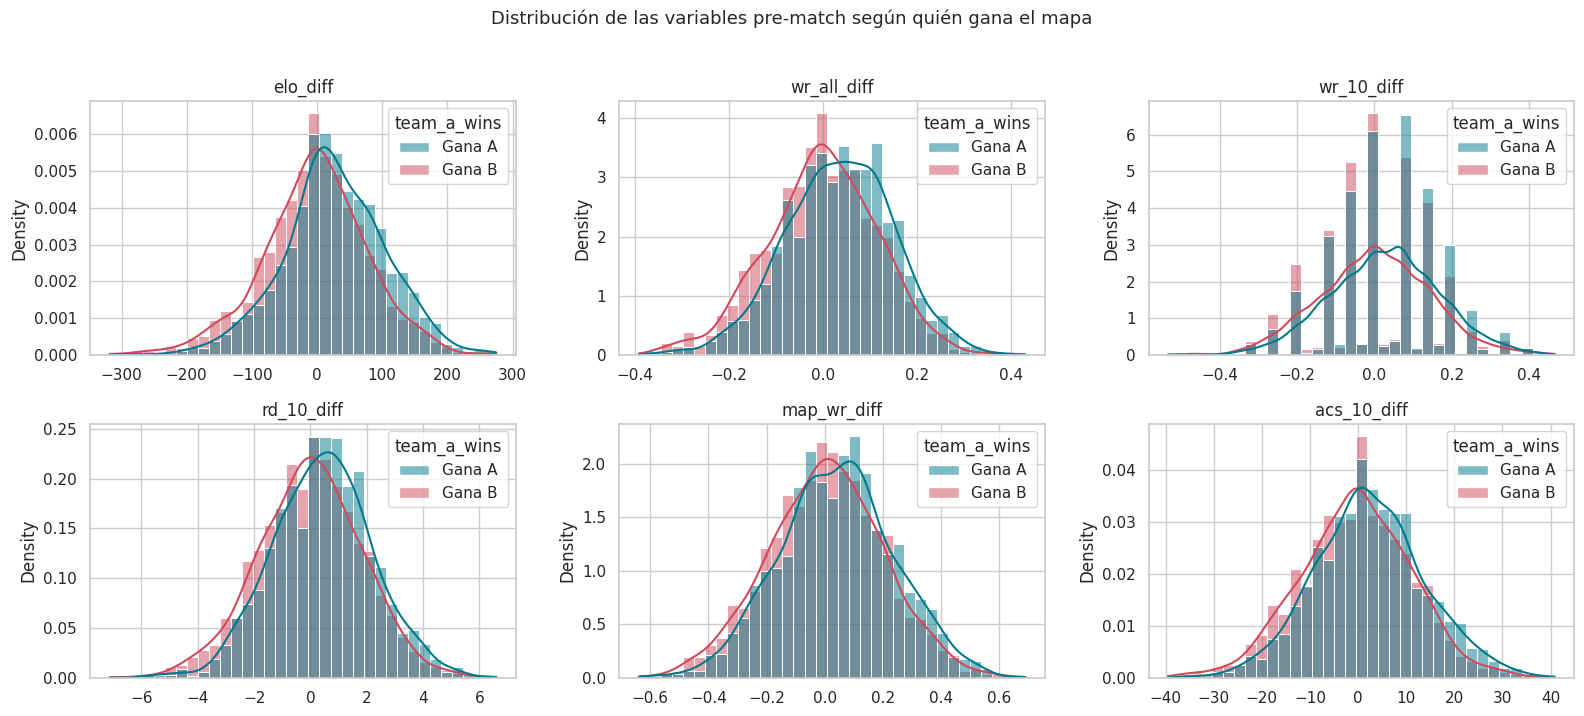

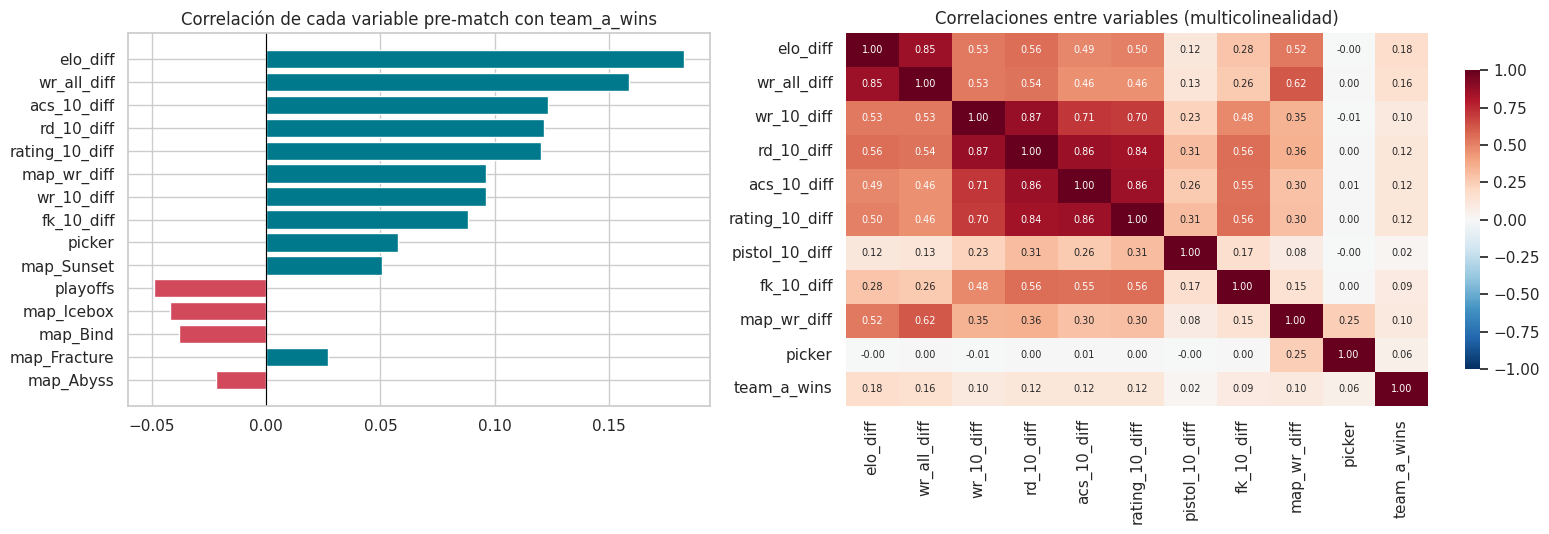

Las variables pre-match tienen correlaciones mucho más débiles con el resultado que las post-match (que llegaban a ~0.80), pero son las únicas utilizables para predecir.
elo_diff          0.183
wr_all_diff       0.159
acs_10_diff       0.123
rd_10_diff        0.121
rating_10_diff    0.120


In [ ]:
#@title **CODE:** distribución de las variables según quién gana
principales = ["elo_diff", "wr_all_diff", "wr_10_diff", "rd_10_diff", "map_wr_diff", "acs_10_diff"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(axes.ravel(), principales):
    sns.histplot(x=X[c], hue=y.map({1: "Gana A", 0: "Gana B"}), kde=True, stat="density",
                 common_norm=False, bins=35, ax=ax, palette={"Gana A": "#00798c", "Gana B": "#d1495b"})
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Distribución de las variables pre-match según quién gana el mapa", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
corr_t = X.corrwith(y).drop(["hist_min"]).sort_values(key=abs, ascending=False).head(15)
axes[0].barh(corr_t.index[::-1], corr_t.values[::-1], color=["#00798c" if v > 0 else "#d1495b" for v in corr_t.values[::-1]])
axes[0].axvline(0, color="black", lw=.8); axes[0].set_title("Correlación de cada variable pre-match con team_a_wins")
cols_h = ["elo_diff", "wr_all_diff", "wr_10_diff", "rd_10_diff", "acs_10_diff", "rating_10_diff", "pistol_10_diff", "fk_10_diff", "map_wr_diff", "picker"]
sns.heatmap(X[cols_h + []].assign(team_a_wins=y).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar_kws={"shrink": .8}, ax=axes[1])
axes[1].set_title("Correlaciones entre variables (multicolinealidad)")
plt.tight_layout(); plt.show()
print("Las variables pre-match tienen correlaciones mucho más débiles con el resultado que las post-match (que llegaban a ~0.80), pero son las únicas utilizables para predecir.")
print(corr_t.head(5).round(3).to_string())

## 3. Protocolo de evaluación y líneas base

Los mapas tienen **orden temporal**: no se puede "mezclar" el futuro con el pasado (si un mapa de 2026 está en entrenamiento, el modelo ya "vio" el desenlace de esa época). Por eso la partición en train / validación / test se hace **por tiempo**:

| Conjunto | Contenido | Para qué |
|---|---|---|
| **Train** | primer 75 % cronológico de 2024–2025 | ajustar el modelo |
| **Validación** | último 25 % de 2024–2025 | comparar configuraciones (aquí se mueven los hiperparámetros) |
| **Test** | **toda la temporada 2026** | se toca **una sola vez**, al final |

Además, cada prueba se evalúa con **validación cruzada temporal** (`TimeSeriesSplit`, 5 pliegues de ventana creciente) dentro de *train*, sin mezclar épocas.

**Puntaje de selección** (para decidir qué configuración es mejor):
$$\text{score} = \tfrac{1}{2}\big(\text{accuracy en validación} + \text{accuracy media en CV temporal}\big)$$
Usamos dos estimaciones independientes para no dejarnos engañar por la suerte de un solo conjunto (la validación tiene ~600 mapas, así que su error típico es de ~2 puntos). El desempate es el log-loss de validación.

,Conjunto,Mapas,% gana Team A,Temporadas
0,Train,1785,51.4,"2024, 2025"
1,Validación,596,51.5,2025
2,Test (2026),886,47.2,2026


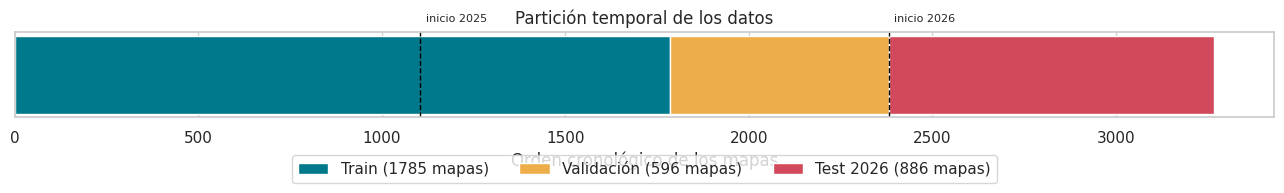

In [ ]:
#@title **CODE:** particiones temporales
es_test = (df.year == 2026).values
idx_dev, idx_test = np.where(~es_test)[0], np.where(es_test)[0]
assert idx_dev.max() < idx_test.min(), "el test debe ser estrictamente posterior al desarrollo"
corte = int(len(idx_dev) * 0.75)
idx_tr, idx_va = idx_dev[:corte], idx_dev[corte:]

X_tr, y_tr = X.iloc[idx_tr], y.iloc[idx_tr]
X_va, y_va = X.iloc[idx_va], y.iloc[idx_va]
X_te, y_te = X.iloc[idx_test], y.iloc[idx_test]
X_dev, y_dev = X.iloc[idx_dev], y.iloc[idx_dev]

resumen_split = pd.DataFrame({
    "Conjunto": ["Train", "Validación", "Test (2026)"],
    "Mapas": [len(y_tr), len(y_va), len(y_te)],
    "% gana Team A": [y_tr.mean()*100, y_va.mean()*100, y_te.mean()*100],
    "Temporadas": [", ".join(map(str, sorted(df.year.iloc[idx_tr].unique()))),
                   ", ".join(map(str, sorted(df.year.iloc[idx_va].unique()))),
                   ", ".join(map(str, sorted(df.year.iloc[idx_test].unique())))]}).round(1)
display(resumen_split)

fig, ax = plt.subplots(figsize=(13, 2.6))
for (a, b, c, nombre) in [(0, corte, "#00798c", "Train"), (corte, len(idx_dev), "#edae49", "Validación"), (len(idx_dev), len(df), "#d1495b", "Test 2026")]:
    ax.barh(0, b - a, left=a, color=c, edgecolor="white", label=f"{nombre} ({b-a} mapas)")
for yr in [2025, 2026]:
    ax.axvline(df.index[df.year == yr][0], color="black", ls="--", lw=1); ax.text(df.index[df.year == yr][0] + 15, 0.55, f"inicio {yr}", fontsize=8)
ax.set_yticks([]); ax.set_xlabel("Orden cronológico de los mapas"); ax.set_title("Partición temporal de los datos"); ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.35))
plt.tight_layout(); plt.show()

> **Dos cosas para notar en la tabla anterior.** (1) En 2026 el Team A gana solo ≈ 47 % de los mapas (≈ 51 % en 2024–2025): el orden "A/B" es arbitrario y su sesgo **cambia con el tiempo**, así que "apostar siempre a A" no es una línea base seria (por eso la tabla siguiente usa reglas con sentido). (2) Es una razón más para probar la perilla `espejo`, que hace al modelo indiferente al orden A/B.

In [ ]:
#@title **CODE:** métricas y reglas simples (las líneas base a superar)
def proba(est, Xm):
    return est.predict_proba(Xm)[:, 1]

def metricas(y_true, p, umbral=0.5):
    """Métricas de clasificación (accuracy, precision, recall, F1, especificidad) y de probabilidad (AUC, log-loss, Brier).
    Clase positiva = 1 = gana Team A. Todas las predicciones se obtienen de la probabilidad (p >= 0.5)."""
    yp = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yp, labels=[0, 1]).ravel()
    return {"acc": accuracy_score(y_true, yp), "prec": precision_score(y_true, yp, zero_division=0),
            "rec": recall_score(y_true, yp, zero_division=0), "esp": tn / (tn + fp) if (tn + fp) else 0.0,
            "f1": f1_score(y_true, yp, zero_division=0), "auc": roc_auc_score(y_true, p),
            "ll": log_loss(y_true, np.clip(p, 1e-6, 1 - 1e-6)), "brier": brier_score_loss(y_true, p)}

def regla(Xm, ym, col):
    """Regla trivial: apostar al equipo con mejor valor de `col` (se ignoran los empates)."""
    v = Xm[col].values; m = v != 0
    return accuracy_score(ym.values[m], (v[m] > 0).astype(int)), int(m.sum())

filas = []
for nombre, (Xm, ym) in {"Validación": (X_va, y_va), "Test 2026": (X_te, y_te)}.items():
    p_elo = 1 / (1 + 10 ** (-Xm["elo_diff"].values / 400))
    filas += [
        {"Conjunto": nombre, "Línea base": "Siempre Team A (≈ moneda)", "accuracy": ym.mean(), "mapas": len(ym), "log-loss": np.nan},
        {"Conjunto": nombre, "Línea base": "Gana el de mejor win rate histórico", "accuracy": regla(Xm, ym, "wr_all_diff")[0], "mapas": regla(Xm, ym, "wr_all_diff")[1], "log-loss": np.nan},
        {"Conjunto": nombre, "Línea base": "Gana el de mayor Elo", "accuracy": regla(Xm, ym, "elo_diff")[0], "mapas": regla(Xm, ym, "elo_diff")[1], "log-loss": log_loss(ym, np.clip(p_elo, 1e-3, 1 - 1e-3))},
        {"Conjunto": nombre, "Línea base": "Gana quien eligió el mapa (sin decider)", "accuracy": regla(Xm, ym, "picker")[0], "mapas": regla(Xm, ym, "picker")[1], "log-loss": np.nan}]
bases = pd.DataFrame(filas)
display(bases.round(4))
ACC_ELO_VAL = bases[(bases.Conjunto == "Validación") & (bases["Línea base"] == "Gana el de mayor Elo")].accuracy.iloc[0]
print(f"\nOjo con la escala del problema: con ~{len(y_va)} mapas de validación el error estándar de una accuracy ≈ 55 % es de ±{100*np.sqrt(.55*.45/len(y_va)):.1f} puntos.")
print("Diferencias menores a ~2-3 puntos entre configuraciones NO son distinguibles del azar.")

,Conjunto,Línea base,accuracy,mapas,log-loss
0,Validación,Siempre Team A (≈ moneda),0.5151,596,NaN
1,Validación,Gana el de mejor win rate histórico,0.5456,592,NaN
2,Validación,Gana el de mayor Elo,0.5574,592,0.6768
3,Validación,Gana quien eligió el mapa (sin decider),0.5288,486,NaN
4,Test 2026,Siempre Team A (≈ moneda),0.4718,886,NaN
5,Test 2026,Gana el de mejor win rate histórico,0.5600,884,NaN
6,Test 2026,Gana el de mayor Elo,0.5937,886,0.6795
7,Test 2026,Gana quien eligió el mapa (sin decider),0.5531,725,NaN



Ojo con la escala del problema: con ~596 mapas de validación el error estándar de una accuracy ≈ 55 % es de ±2.0 puntos.
Diferencias menores a ~2-3 puntos entre configuraciones NO son distinguibles del azar.


## 4. Infraestructura de experimentos (el "cuaderno de laboratorio")

Para poder **mover hiperparámetros, registrar cada prueba y explicar qué cambió**, definimos una función `prueba()` que hace siempre lo mismo:

1. Toma como punto de partida la **mejor prueba guiada hasta ese momento** del modelo (*búsqueda codiciosa*: se mueve algo, se mide, y si mejora se convierte en la nueva referencia).
2. Aplica **solo los cambios indicados** (así sabemos exactamente qué provocó la diferencia).
3. Entrena en *train*, mide en *train* y en *validación*, y hace la **validación cruzada temporal**.
4. Guarda una fila en el registro con: `id`, la **referencia**, **qué cambió** (`valor anterior → valor nuevo`), la **hipótesis**, todos los hiperparámetros, las métricas, el tiempo y un **veredicto** (▲ mejora / ≈ igual / ▼ empeora) comparando el puntaje de selección con la referencia. Una diferencia menor a ±0.003 se considera ruido.

Además de los hiperparámetros propios de cada modelo, movemos dos "perillas" de datos:

- **`features`**: qué conjunto de variables usa el modelo (`elo` → 1 variable; `basica` → 4; `nucleo` → 8; `completa` → 29, con indicadores de mapa, región y fase).
- **`espejo`**: el orden "Team A / Team B" es arbitrario (en vlr.gg es el primer equipo listado). Con `espejo=True` el modelo se entrena con cada mapa **y con su versión invertida** (A↔B, se cambia el signo de las diferencias y se invierte la etiqueta) y al predecir se promedian ambas lecturas. Así el modelo no puede aprender sesgos del orden y duplica los datos de entrenamiento.

> El **test no se mira en ningún momento** de esta sección. Todo se decide con validación y validación cruzada.

In [ ]:
#@title **CODE:** conjuntos de variables, modelo "espejo" y fábrica de modelos
CONJUNTOS = {
    "elo":      ["elo_diff"],
    "basica":   ["elo_diff", "wr_all_diff", "wr_10_diff", "picker"],
    "nucleo":   ["elo_diff", "wr_all_diff", "wr_10_diff", "rd_10_diff", "acs_10_diff", "map_wr_diff", "picker", "hist_min"],
    "completa": list(X.columns),
    "dos_vars": ["elo_diff", "wr_10_diff"],        # solo para dibujar fronteras de decisión
}

class EspejoAB(ClassifierMixin, BaseEstimator):
    """Envuelve cualquier clasificador para hacerlo simétrico respecto al orden A/B."""
    def __init__(self, estimador=None, cols_antisim=None):
        self.estimador = estimador; self.cols_antisim = cols_antisim
    def _invertir(self, Xm):
        Xi = Xm.copy(); Xi[self.cols_antisim] = -Xi[self.cols_antisim]; return Xi
    def fit(self, Xm, ym):
        ym = np.asarray(ym)
        Xa = pd.concat([Xm, self._invertir(Xm)], ignore_index=True)
        self.estimador_ = clone(self.estimador).fit(Xa, np.concatenate([ym, 1 - ym]))
        self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, Xm):
        p1 = self.estimador_.predict_proba(Xm)[:, 1]
        p2 = self.estimador_.predict_proba(self._invertir(Xm))[:, 1]
        p = (p1 + (1 - p2)) / 2
        return np.column_stack([1 - p, p])
    def predict(self, Xm):
        return (self.predict_proba(Xm)[:, 1] >= 0.5).astype(int)

def construir_modelo(modelo, params):
    """Convierte un diccionario de parámetros en un estimador de sklearn + la lista de columnas que usa."""
    p = dict(params); fs = p.pop("features"); espejo = p.pop("espejo", False); cols = CONJUNTOS[fs]
    if   modelo == "GNB": est = GaussianNB(**p)
    elif modelo == "DT":  est = DecisionTreeClassifier(random_state=SEED, **p)
    elif modelo == "RF":  est = RandomForestClassifier(random_state=SEED, n_jobs=-1, **p)
    elif modelo == "SVM": est = make_pipeline(StandardScaler(), SVC(probability=True, random_state=SEED, **p))   # el escalado se ajusta solo con los datos de entrenamiento
    if espejo:
        est = EspejoAB(est, [c for c in cols if c.endswith("_diff") or c == "picker"])
    return est, cols

def desenvolver(est):
    """Devuelve el estimador interno (útil para dibujar el árbol o leer importancias)."""
    est = est.estimador_ if isinstance(est, EspejoAB) else est
    return est.steps[-1][1] if hasattr(est, "steps") else est

In [ ]:
#@title **CODE:** `prueba()` — entrena, evalúa y REGISTRA cada experimento
REGISTRO = []            # aquí se guarda absolutamente cada prueba
UMBRAL_RUIDO = 0.003     # diferencias menores a esto se consideran ruido

def evaluar(est, cols):
    t0 = time.time()
    est.fit(X_tr[cols], y_tr)
    p_tr, p_va = proba(est, X_tr[cols]), proba(est, X_va[cols])
    dur = time.time() - t0
    accs, lls = [], []                                      # validación cruzada temporal (ventana creciente)
    for a, b in TimeSeriesSplit(n_splits=5).split(X_tr):
        m = clone(est).fit(X_tr.iloc[a][cols], y_tr.iloc[a])
        pb = proba(m, X_tr.iloc[b][cols])
        accs.append(accuracy_score(y_tr.iloc[b], pb >= 0.5)); lls.append(log_loss(y_tr.iloc[b], np.clip(pb, 1e-6, 1 - 1e-6)))
    return {"tr": metricas(y_tr, p_tr), "va": metricas(y_va, p_va), "cv_acc": np.mean(accs), "cv_std": np.std(accs),
            "cv_ll": np.mean(lls), "t": dur}

def mejor_guiada(modelo):
    cand = [r for r in REGISTRO if r["modelo"] == modelo and r["tipo"] == "guiada"]
    return max(cand, key=lambda r: r["score_sel"]) if cand else None     # en empate conserva la más antigua

def prueba(modelo, cambios=None, hipotesis="", params=None, tipo="guiada", verbose=True):
    """Si `params` es None, parte de la mejor prueba guiada del modelo y le aplica SOLO `cambios`."""
    ref = mejor_guiada(modelo)
    if params is None:
        params = {**ref["params"], **cambios}
        que_cambio = " | ".join(f"{k}: {ref['params'].get(k, '—')} → {v}" for k, v in cambios.items())
    else:
        que_cambio = "(configuración inicial)"
    est, cols = construir_modelo(modelo, params)
    r = evaluar(est, cols)
    score = (r["va"]["acc"] + r["cv_acc"]) / 2
    delta = score - ref["score_sel"] if ref else np.nan
    veredicto = "base" if ref is None else ("▲ mejora" if delta >= UMBRAL_RUIDO else ("▼ empeora" if delta <= -UMBRAL_RUIDO else "≈ igual"))
    n = sum(f["modelo"] == modelo for f in REGISTRO) + 1
    fila = {"id": f"{modelo}-{n:02d}", "modelo": modelo, "tipo": tipo, "referencia": ref["id"] if ref else "—",
            "cambió": que_cambio, "hipótesis": hipotesis, "params": params, "n_vars": len(cols),
            "train_acc": r["tr"]["acc"], "val_acc": r["va"]["acc"], "val_prec": r["va"]["prec"], "val_rec": r["va"]["rec"],
            "val_f1": r["va"]["f1"], "val_auc": r["va"]["auc"], "val_ll": r["va"]["ll"], "val_brier": r["va"]["brier"],
            "cv_acc": r["cv_acc"], "cv_std": r["cv_std"], "cv_ll": r["cv_ll"],
            "gap": r["tr"]["acc"] - r["va"]["acc"], "score_sel": score, "delta_vs_ref": delta, "veredicto": veredicto, "t_seg": r["t"]}
    REGISTRO.append(fila)
    if verbose:
        print(f"[{fila['id']}] {que_cambio:<58s} | train {fila['train_acc']:.3f}  val {fila['val_acc']:.3f}  "
              f"cv {fila['cv_acc']:.3f}±{fila['cv_std']:.3f}  logloss {fila['val_ll']:.3f} | {veredicto}")
    return fila

def registro_df():
    d = pd.DataFrame(REGISTRO); d["params"] = d["params"].apply(lambda p: json.dumps(p, default=str)); return d

COLS_TABLA = ["id", "referencia", "cambió", "train_acc", "val_acc", "cv_acc", "cv_std", "val_ll", "gap", "score_sel", "veredicto"]
def tabla_modelo(modelo, tipo="guiada"):
    r = registro_df(); r = r[(r.modelo == modelo) & (r.tipo == tipo)]
    return r[COLS_TABLA].round(4).reset_index(drop=True)

def mejor_global(modelo):
    """La mejor configuración del modelo entre TODAS sus pruebas (guiadas + barridos). Desempate: menor log-loss."""
    cand = [r for r in REGISTRO if r["modelo"] == modelo]
    return min(cand, key=lambda r: (-round(r["score_sel"], 6), r["val_ll"]))

def grafica_pruebas(modelo, tipo="guiada"):
    r = registro_df(); r = r[(r.modelo == modelo) & (r.tipo == tipo)].reset_index(drop=True)
    mejor = r.score_sel.idxmax()
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(r) + 2.2))
    pos = np.arange(len(r))[::-1]
    ax.barh(pos + 0.2, r.train_acc, height=0.36, color="#c9c9c9", label="Train")
    ax.barh(pos - 0.2, r.val_acc, height=0.36, color=COLORES[modelo], label="Validación")
    ax.errorbar(r.cv_acc, pos - 0.2, xerr=r.cv_std, fmt="o", color="black", ms=4, lw=1, label="CV temporal (media ± std)")
    ax.axvline(0.5, color="black", ls=":", lw=1); ax.axvline(ACC_ELO_VAL, color="#d1495b", ls="--", lw=1.2, label=f"Regla 'mayor Elo' en validación ({ACC_ELO_VAL:.3f})")
    ax.set_yticks(pos); ax.set_yticklabels([f"{i}  {c[:46]}" for i, c in zip(r.id, r["cambió"])], fontsize=8)
    xmax = max(0.66, r.train_acc.max() + 0.03); ax.set_xlim(0.45, xmax)
    ax.text(xmax - 0.004, pos[mejor], "★ mejor", va="center", ha="right", fontsize=10, fontweight="bold", color="#b8860b")
    ax.set_xlabel("Accuracy"); ax.set_title(f"{NOMBRES[modelo]} — pruebas guiadas: ¿qué se movió y qué pasó?")
    ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

def resumen_modelo(modelo):
    guiadas = [r for r in REGISTRO if r["modelo"] == modelo and r["tipo"] == "guiada"]
    base, mj = guiadas[0], mejor_guiada(modelo)
    print(f"{NOMBRES[modelo]}: {len(guiadas)} pruebas guiadas.")
    print(f"  Base      {base['id']}: val {base['val_acc']:.3f} | cv {base['cv_acc']:.3f} | score {base['score_sel']:.4f} | gap train-val {base['gap']:+.3f}")
    print(f"  Mejor     {mj['id']}: val {mj['val_acc']:.3f} | cv {mj['cv_acc']:.3f} | score {mj['score_sel']:.4f} | gap train-val {mj['gap']:+.3f}")
    print(f"  Mejora del score vs la base: {mj['score_sel'] - base['score_sel']:+.4f}")
    print(f"  Configuración: {json.dumps(mj['params'], default=str)}")
print("Infraestructura lista. Cada llamada a prueba() deja una fila en REGISTRO.")

Infraestructura lista. Cada llamada a prueba() deja una fila en REGISTRO.


## 5. Modelo 1 — Gaussian Naive Bayes (GNB)

**Hiperparámetros / perillas que podemos mover:**
- `var_smoothing`: fracción de la varianza máxima que se suma a todas las varianzas (estabiliza y evita gaussianas demasiado "puntiagudas").
- `priors`: probabilidades a priori de cada clase (por defecto se estiman de los datos).
- `features` y `espejo` (ver sección 4).

**Hipótesis:** GNB asume que las variables son independientes dada la clase. Aquí tenemos variables **muy correlacionadas** entre sí (Elo, win rate, forma reciente miden casi lo mismo) y, además, indicadores 0/1 (mapa, región) que no son nada gaussianos. Por eso la hipótesis central es que **menos variables = mejor GNB**.

In [ ]:
#@title **EXPERIMENTOS GNB** — cada línea es una prueba registrada
prueba("GNB", params=dict(features="completa", var_smoothing=1e-9, espejo=False),
       hipotesis="Línea base: GNB con todas las variables y los valores por defecto de sklearn.")

ensayos_gnb = [
    (dict(features="nucleo"),     "Quitar indicadores de mapa/región/fase (no gaussianos) y variables con muchos nulos: menos redundancia."),
    (dict(features="basica"),     "Aún menos variables: solo Elo, win rates y quién eligió el mapa."),
    (dict(features="elo"),        "Caso extremo: una sola variable (equivale a la regla del Elo, pero con gaussianas por clase)."),
    (dict(var_smoothing=1e-6),    "Suavizar un poco las varianzas por si alguna gaussiana quedó muy estrecha."),
    (dict(var_smoothing=1e-3),    "Suavizado moderado."),
    (dict(var_smoothing=1e-1),    "Suavizado fuerte: las varianzas se inflan, el modelo se vuelve más 'tímido'."),
    (dict(priors=[0.5, 0.5]),     "Forzar priors 50/50: Team A es solo el primer equipo listado, no el favorito."),
    (dict(espejo=True),           "Entrenar con los mapas y sus versiones A↔B: el modelo queda simétrico y con el doble de datos."),
]
for cambios, hip in ensayos_gnb:
    prueba("GNB", cambios, hip)

[GNB-01] (configuración inicial)                                    | train 0.575  val 0.552  cv 0.562±0.041  logloss 0.920 | base
[GNB-02] features: completa → nucleo                                | train 0.568  val 0.554  cv 0.576±0.024  logloss 0.798 | ▲ mejora


[GNB-03] features: nucleo → basica                                  | train 0.565  val 0.554  cv 0.577±0.025  logloss 0.711 | ≈ igual
[GNB-04] features: basica → elo                                     | train 0.570  val 0.555  cv 0.592±0.016  logloss 0.677 | ▲ mejora


[GNB-05] var_smoothing: 1e-09 → 1e-06                               | train 0.570  val 0.555  cv 0.592±0.016  logloss 0.677 | ≈ igual
[GNB-06] var_smoothing: 1e-09 → 0.001                               | train 0.569  val 0.555  cv 0.592±0.016  logloss 0.677 | ≈ igual


[GNB-07] var_smoothing: 1e-09 → 0.1                                 | train 0.574  val 0.557  cv 0.590±0.016  logloss 0.676 | ≈ igual
[GNB-08] priors: — → [0.5, 0.5]                                     | train 0.565  val 0.559  cv 0.582±0.027  logloss 0.678 | ▼ empeora


[GNB-09] espejo: False → True                                       | train 0.573  val 0.557  cv 0.582±0.018  logloss 0.676 | ▼ empeora


,id,referencia,cambió,train_acc,val_acc,cv_acc,cv_std,val_ll,gap,score_sel,veredicto
0,GNB-01,—,(configuración inicial),0.5748,0.5520,0.5623,0.0409,0.9197,0.0228,0.5572,base
1,GNB-02,GNB-01,features: completa → nucleo,0.5675,0.5537,0.5764,0.0238,0.7979,0.0138,0.5651,▲ mejora
2,GNB-03,GNB-02,features: nucleo → basica,0.5653,0.5537,0.5771,0.0245,0.7109,0.0116,0.5654,≈ igual
3,GNB-04,GNB-03,features: basica → elo,0.5697,0.5554,0.5919,0.0158,0.6773,0.0144,0.5736,▲ mejora
4,GNB-05,GNB-04,var_smoothing: 1e-09 → 1e-06,0.5697,0.5554,0.5919,0.0158,0.6773,0.0144,0.5736,≈ igual
5,GNB-06,GNB-04,var_smoothing: 1e-09 → 0.001,0.5692,0.5554,0.5919,0.0158,0.6773,0.0138,0.5736,≈ igual
6,GNB-07,GNB-04,var_smoothing: 1e-09 → 0.1,0.5737,0.5570,0.5899,0.0158,0.6761,0.0166,0.5735,≈ igual
7,GNB-08,GNB-04,"priors: — → [0.5, 0.5]",0.5653,0.5587,0.5818,0.0274,0.6783,0.0065,0.5703,▼ empeora
8,GNB-09,GNB-04,espejo: False → True,0.5731,0.5570,0.5825,0.0183,0.6756,0.0161,0.5698,▼ empeora


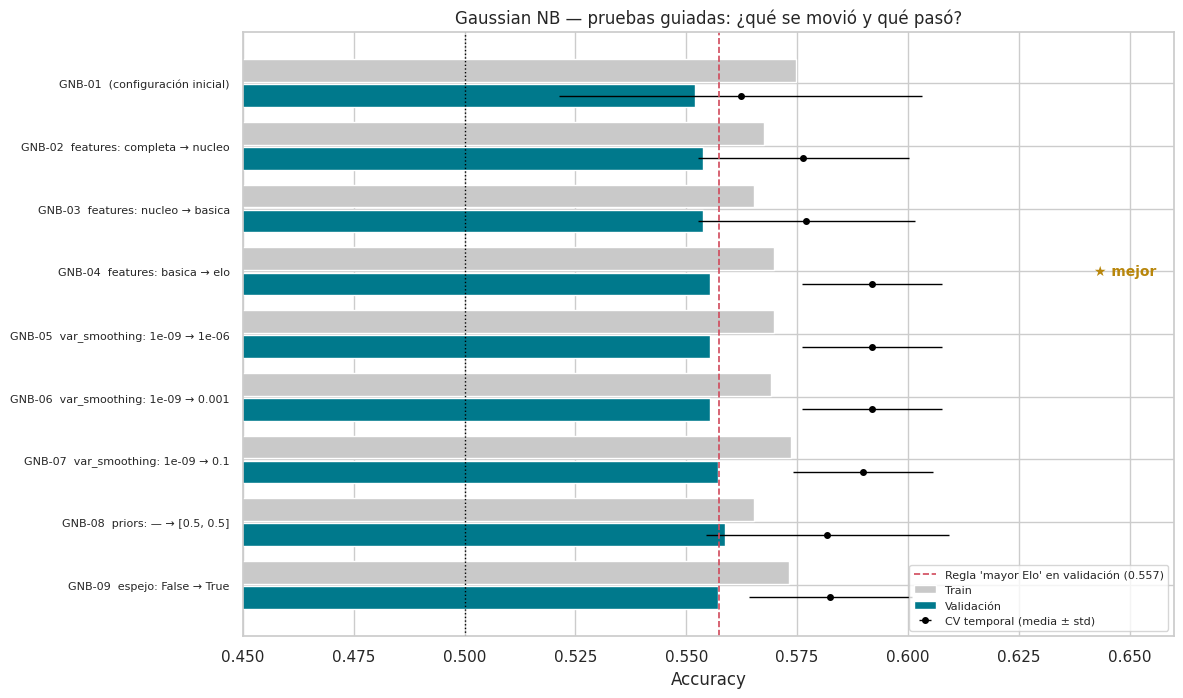

Gaussian NB: 9 pruebas guiadas.
  Base      GNB-01: val 0.552 | cv 0.562 | score 0.5572 | gap train-val +0.023
  Mejor     GNB-04: val 0.555 | cv 0.592 | score 0.5736 | gap train-val +0.014
  Mejora del score vs la base: +0.0165
  Configuración: {"features": "elo", "var_smoothing": 1e-09, "espejo": false}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas de GNB
display(tabla_modelo("GNB"))
grafica_pruebas("GNB")
resumen_modelo("GNB")

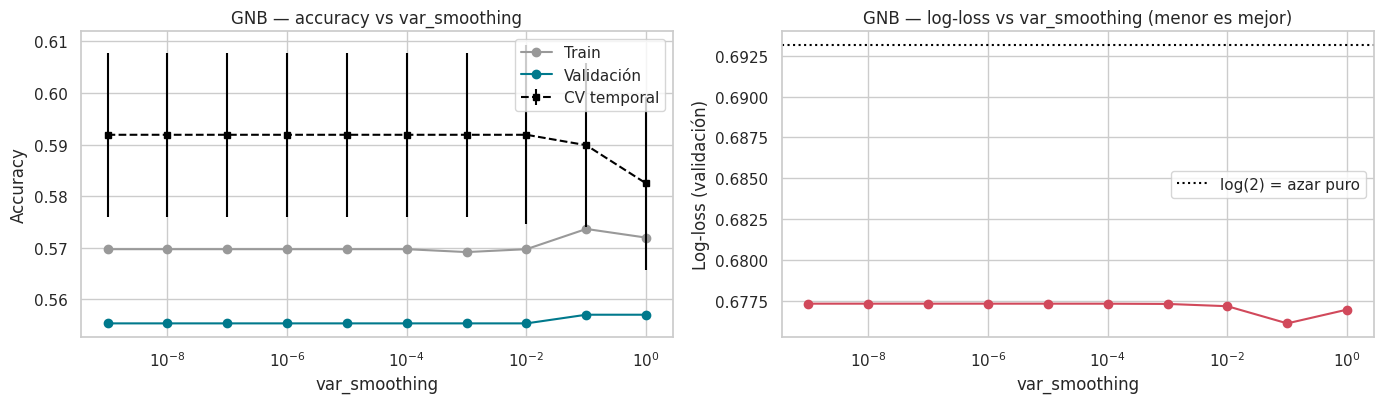

In [ ]:
#@title **BARRIDO GNB:** efecto de `var_smoothing` (10 valores en escala logarítmica, registrados como 'barrido')
for vs in np.logspace(-9, 0, 10):
    prueba("GNB", dict(var_smoothing=float(vs)), f"Barrido de var_smoothing = {vs:.0e} (resto igual a la mejor prueba guiada)", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "GNB") & (r.tipo == "barrido")].copy()
b["vs"] = b["params"].apply(lambda s: json.loads(s)["var_smoothing"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(b.vs, b.train_acc, "o-", color="#999999", label="Train"); ax[0].plot(b.vs, b.val_acc, "o-", color=COLORES["GNB"], label="Validación")
ax[0].errorbar(b.vs, b.cv_acc, yerr=b.cv_std, fmt="s--", color="black", ms=4, label="CV temporal")
ax[0].set_xscale("log"); ax[0].set_xlabel("var_smoothing"); ax[0].set_ylabel("Accuracy"); ax[0].set_title("GNB — accuracy vs var_smoothing"); ax[0].legend()
ax[1].plot(b.vs, b.val_ll, "o-", color="#d1495b"); ax[1].axhline(np.log(2), color="black", ls=":", label="log(2) = azar puro")
ax[1].set_xscale("log"); ax[1].set_xlabel("var_smoothing"); ax[1].set_ylabel("Log-loss (validación)"); ax[1].set_title("GNB — log-loss vs var_smoothing (menor es mejor)"); ax[1].legend()
plt.tight_layout(); plt.show()

### 📖 Lectura de los resultados de GNB
- **Línea base (29 variables): la peor.** Accuracy en validación ≈ 0.55, pero sobre todo un **log-loss de 0.92** (peor que tirar una moneda, que da 0.693): con variables muy correlacionadas e indicadores 0/1 el modelo se vuelve *excesivamente seguro de sí mismo*, y se equivoca con mucha convicción.
- **Menos variables = mejores probabilidades.** El log-loss bajó 0.920 → 0.798 (núcleo) → 0.711 (básica) → **0.677 (solo Elo)**, y la accuracy en CV subió de 0.56 a 0.59. Se confirma la hipótesis: el supuesto de independencia de Naive Bayes se rompe cuando las variables miden lo mismo.
- **`var_smoothing` casi no importa** entre 1e-9 y 1e-3 (resultados idénticos): con una sola variable de varianza enorme, el suavizado es irrelevante. Solo a partir de ~0.1 empieza a notarse algo.
- **`priors` 50/50 y `espejo` no ayudaron** (▼): las clases ya están equilibradas y, con una sola variable antisimétrica, el modelo ya es casi simétrico.
- **Mejor GNB = una sola variable (`elo_diff`).** En el fondo es la regla "gana el de mayor Elo", pero entregando probabilidades.

## 6. Modelo 2 — Árbol de Decisión (DT)

**Hiperparámetros que movemos:**
- `max_depth`: profundidad máxima (principal control del sobreajuste).
- `min_samples_leaf`: mínimo de mapas por hoja (evita hojas con 1–2 mapas).
- `criterion`: `gini` o `entropy` para medir la impureza.
- `max_features`: variables candidatas en cada corte (`None` = todas).
- `ccp_alpha`: poda por costo-complejidad (corta ramas que aportan poco).
- `features` y `espejo`.

**Hipótesis central:** con ~1,800 mapas de entrenamiento y señal débil, el árbol **sin límite sobreajustará brutalmente** (casi 100 % en train y ~50 % en validación), y los mejores resultados vendrán de árboles **muy poco profundos y con hojas grandes**.

In [ ]:
#@title **EXPERIMENTOS DT** — cada línea es una prueba registrada
prueba("DT", params=dict(features="nucleo", criterion="gini", max_depth=None, min_samples_leaf=1, max_features=None, ccp_alpha=0.0, espejo=False),
       hipotesis="Línea base: árbol sin ningún límite (hará sobreajuste: memoriza el entrenamiento).")

ensayos_dt = [
    (dict(max_depth=3),            "Limitar la profundidad a 3 para frenar la memorización."),
    (dict(max_depth=2),            "Aún más simple: solo 2 niveles."),
    (dict(max_depth=5),            "Probar el otro lado: ¿un poco más de profundidad ayuda?"),
    (dict(min_samples_leaf=25),    "Exigir al menos 25 mapas por hoja: predicciones más estables."),
    (dict(min_samples_leaf=60),    "Hojas aún más grandes (60 mapas)."),
    (dict(criterion="entropy"),    "Cambiar el criterio de corte de Gini a entropía."),
    (dict(max_features="sqrt"),    "Considerar solo √p variables por corte (más aleatoriedad, menos dependencia de una sola variable)."),
    (dict(ccp_alpha=0.003),        "Poda por costo-complejidad: cortar ramas que casi no reducen el error."),
    (dict(features="basica"),      "Dar menos variables al árbol (4) para que no se distraiga con ruido."),
    (dict(features="completa"),    "Dar todas las variables (29), incluyendo mapa, región y fase."),
    (dict(espejo=True),            "Árbol simétrico: entrenar con el mapa y su versión A↔B."),
]
for cambios, hip in ensayos_dt:
    prueba("DT", cambios, hip)

[DT-01] (configuración inicial)                                    | train 0.995  val 0.513  cv 0.497±0.024  logloss 6.722 | base
[DT-02] max_depth: None → 3                                        | train 0.594  val 0.565  cv 0.549±0.026  logloss 0.694 | ▲ mejora
[DT-03] max_depth: 3 → 2                                           | train 0.579  val 0.560  cv 0.555±0.024  logloss 0.685 | ≈ igual


[DT-04] max_depth: 2 → 5                                           | train 0.635  val 0.540  cv 0.521±0.041  logloss 0.942 | ▼ empeora
[DT-05] min_samples_leaf: 1 → 25                                   | train 0.579  val 0.560  cv 0.539±0.039  logloss 0.685 | ▼ empeora
[DT-06] min_samples_leaf: 1 → 60                                   | train 0.579  val 0.560  cv 0.533±0.050  logloss 0.685 | ▼ empeora


[DT-07] criterion: gini → entropy                                  | train 0.579  val 0.560  cv 0.558±0.021  logloss 0.685 | ≈ igual
[DT-08] max_features: None → sqrt                                  | train 0.568  val 0.537  cv 0.552±0.043  logloss 0.691 | ▼ empeora
[DT-09] ccp_alpha: 0.0 → 0.003                                     | train 0.579  val 0.560  cv 0.558±0.021  logloss 0.685 | ≈ igual
[DT-10] features: nucleo → basica                                  | train 0.579  val 0.560  cv 0.558±0.021  logloss 0.685 | ≈ igual


[DT-11] features: nucleo → completa                                | train 0.579  val 0.560  cv 0.558±0.021  logloss 0.685 | ≈ igual
[DT-12] espejo: False → True                                       | train 0.578  val 0.559  cv 0.562±0.027  logloss 0.686 | ≈ igual


,id,referencia,cambió,train_acc,val_acc,cv_acc,cv_std,val_ll,gap,score_sel,veredicto
0,DT-01,—,(configuración inicial),0.9950,0.5134,0.4970,0.0236,6.7223,0.4815,0.5052,base
1,DT-02,DT-01,max_depth: None → 3,0.5944,0.5654,0.5488,0.0260,0.6944,0.0290,0.5571,▲ mejora
2,DT-03,DT-02,max_depth: 3 → 2,0.5787,0.5604,0.5549,0.0236,0.6849,0.0183,0.5576,≈ igual
3,DT-04,DT-03,max_depth: 2 → 5,0.6353,0.5403,0.5212,0.0414,0.9419,0.0950,0.5307,▼ empeora
4,DT-05,DT-03,min_samples_leaf: 1 → 25,0.5787,0.5604,0.5387,0.0389,0.6849,0.0183,0.5496,▼ empeora
5,DT-06,DT-03,min_samples_leaf: 1 → 60,0.5787,0.5604,0.5327,0.0500,0.6849,0.0183,0.5465,▼ empeora
6,DT-07,DT-03,criterion: gini → entropy,0.5787,0.5604,0.5576,0.0210,0.6849,0.0183,0.5590,≈ igual
7,DT-08,DT-07,max_features: None → sqrt,0.5675,0.5369,0.5522,0.0427,0.6909,0.0306,0.5446,▼ empeora
8,DT-09,DT-07,ccp_alpha: 0.0 → 0.003,0.5787,0.5604,0.5576,0.0210,0.6849,0.0183,0.5590,≈ igual
9,DT-10,DT-07,features: nucleo → basica,0.5787,0.5604,0.5576,0.0210,0.6849,0.0183,0.5590,≈ igual


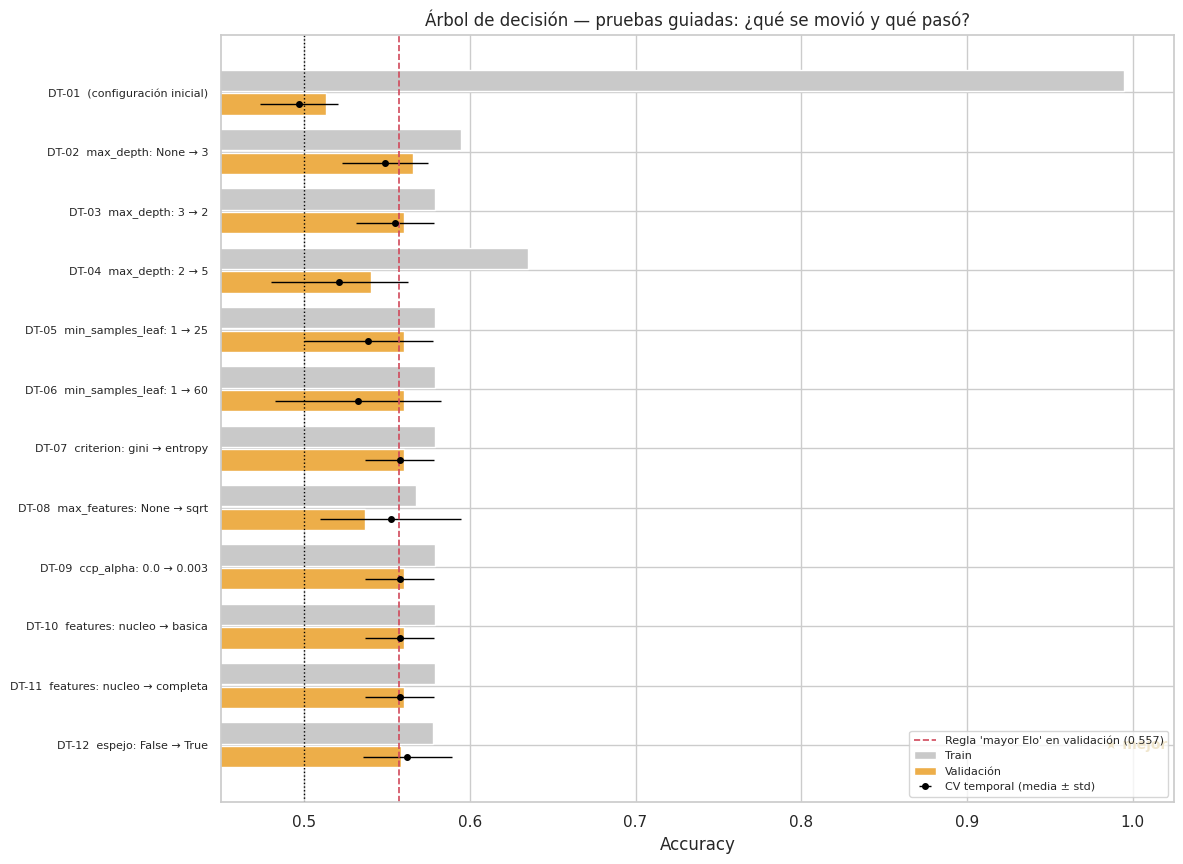

Árbol de decisión: 12 pruebas guiadas.
  Base      DT-01: val 0.513 | cv 0.497 | score 0.5052 | gap train-val +0.482
  Mejor     DT-12: val 0.559 | cv 0.562 | score 0.5605 | gap train-val +0.019
  Mejora del score vs la base: +0.0553
  Configuración: {"features": "nucleo", "criterion": "entropy", "max_depth": 2, "min_samples_leaf": 1, "max_features": null, "ccp_alpha": 0.0, "espejo": true}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas de DT
display(tabla_modelo("DT"))
grafica_pruebas("DT")
resumen_modelo("DT")

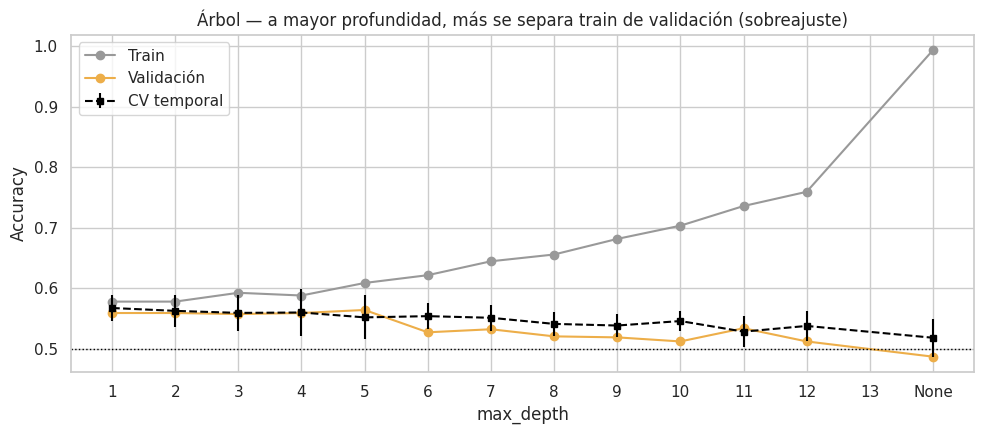

In [ ]:
#@title **BARRIDO DT:** curva de sobreajuste — accuracy en train / validación / CV según `max_depth`
for d in list(range(1, 13)) + [None]:
    prueba("DT", dict(max_depth=d), f"Barrido de max_depth = {d} (resto igual a la mejor prueba guiada)", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "DT") & (r.tipo == "barrido")].copy()
b["depth"] = b["params"].apply(lambda s: json.loads(s)["max_depth"]); b["depth_num"] = b["depth"].fillna(14).astype(float)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(b.depth_num, b.train_acc, "o-", color="#999999", label="Train"); ax.plot(b.depth_num, b.val_acc, "o-", color=COLORES["DT"], label="Validación")
ax.errorbar(b.depth_num, b.cv_acc, yerr=b.cv_std, fmt="s--", color="black", ms=4, label="CV temporal")
ax.set_xticks(list(range(1, 14)) + [14]); ax.set_xticklabels([str(i) for i in range(1, 14)] + ["None"])
ax.axhline(0.5, color="black", ls=":", lw=1); ax.set_xlabel("max_depth"); ax.set_ylabel("Accuracy"); ax.set_title("Árbol — a mayor profundidad, más se separa train de validación (sobreajuste)")
ax.legend(); plt.tight_layout(); plt.show()

Mejor árbol de todas las pruebas: DT-13 — {"features": "nucleo", "criterion": "entropy", "max_depth": 1, "min_samples_leaf": 1, "max_features": null, "ccp_alpha": 0.0, "espejo": true}
|--- elo_diff <= -8.37
|   |--- class: 0
|--- elo_diff >  -8.37
|   |--- class: 1



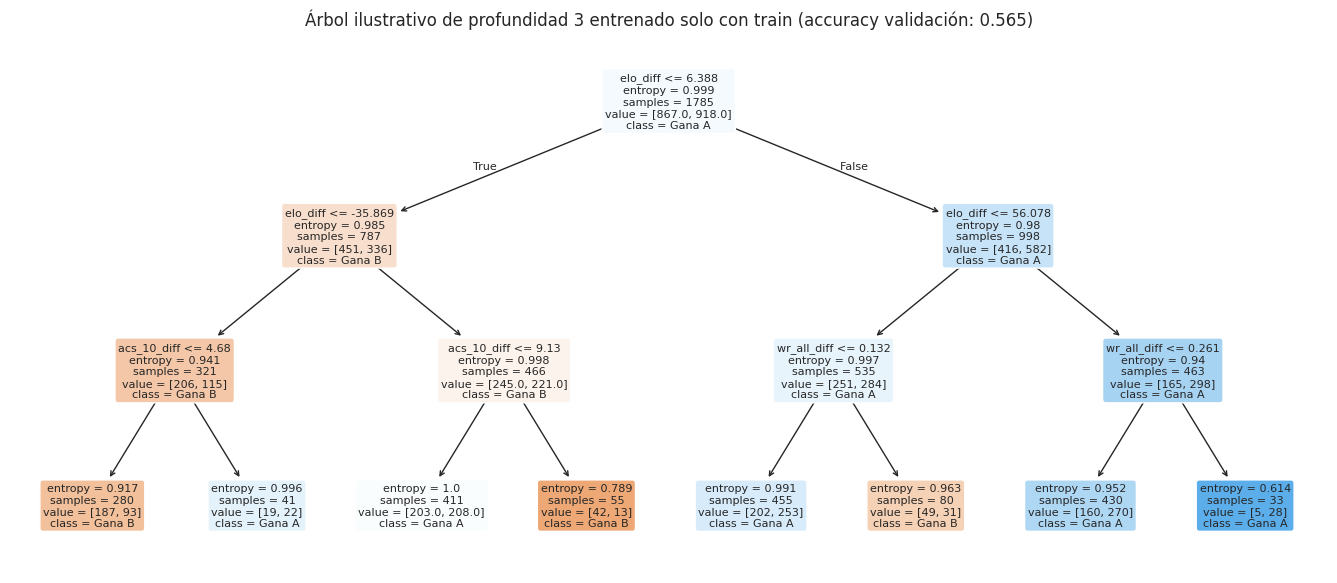

,elo_diff,acs_10_diff,wr_all_diff
Importancia (impureza),0.648,0.205,0.147


In [ ]:
#@title **GRÁFICA:** el mejor árbol
from sklearn.tree import export_text
cfg = mejor_global("DT"); est, cols = construir_modelo("DT", cfg["params"]); est.fit(X_tr[cols], y_tr)
print(f"Mejor árbol de todas las pruebas: {cfg['id']} — {json.dumps(cfg['params'], default=str)}")
print(export_text(desenvolver(est), feature_names=cols))

# El mejor árbol puede ser tan simple (1 corte) que no hay mucho que dibujar. Para ver cómo "piensa" un árbol,
# dibujamos uno ilustrativo de profundidad 3 con la misma configuración (sin espejo):
p_ilus = {**cfg["params"], "max_depth": 3, "espejo": False}
est3, cols3 = construir_modelo("DT", p_ilus); est3.fit(X_tr[cols3], y_tr); arbol3 = desenvolver(est3)
fig, ax = plt.subplots(figsize=(17, 7))
plot_tree(arbol3, feature_names=cols3, class_names=["Gana B", "Gana A"], filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Árbol ilustrativo de profundidad 3 entrenado solo con train (accuracy validación: {accuracy_score(y_va, proba(est3, X_va[cols3]) >= .5):.3f})"); plt.show()
imp = pd.Series(arbol3.feature_importances_, index=cols3).sort_values(ascending=False)
display(imp[imp > 0].rename("Importancia (impureza)").round(3).to_frame().T)

### 📖 Lectura de los resultados del Árbol
- **Sobreajuste extremo en la línea base:** sin límites, el árbol llega a ≈ 99.5 % en train y cae a ≈ 51 % en validación (≈ 50 % en CV) con un log-loss de 6.7: memoriza el pasado y no generaliza.
- **Limitar la profundidad fue lo que más ayudó:** con `max_depth=3` la validación sube ≈ 5 puntos y el log-loss baja de 6.7 a 0.69. Con `max_depth=5` empeora otra vez. En el barrido se ve que la separación train/validación crece sin parar al profundizar.
- **Varias pruebas dieron resultados idénticos** (poda `ccp_alpha` y cambiar el conjunto de variables; la entropía apenas movió la CV): el árbol de profundidad 2 ya estaba usando siempre los mismos cortes (basados en Elo), así que esos cambios no tenían nada que mover. También es información: *no todo hiperparámetro importa en todos los contextos*.
- `min_samples_leaf` grande **empeoró** la CV y `max_features='sqrt'` **empeoró** la validación (≈ 0.56 → 0.54): quitarle variables a un árbol que ya usa pocas solo le quita opciones.
- **El mejor árbol de todas las pruebas es un "tocón" de un solo corte sobre `elo_diff`**, es decir, otra vez la regla del Elo.

## 7. Modelo 3 — Random Forest (RF)

**Hiperparámetros que movemos:**
- `n_estimators`: número de árboles.
- `max_depth` y `min_samples_leaf`: complejidad de cada árbol.
- `max_features`: variables por corte (`sqrt`, o una fracción del total).
- `max_samples`: fracción de mapas que ve cada árbol (más baja = árboles más distintos entre sí).
- `features` y `espejo`.

**Hipótesis central:** el RF con árboles profundos tendrá casi 100 % en train y sobreajustará; **regularizarlo** (hojas más grandes, menos profundidad) debería acercarlo al nivel del Elo. Como en el DT, esperamos que *añadir más variables no ayude* (más ruido que señal).

In [ ]:
#@title **EXPERIMENTOS RF** — cada línea es una prueba registrada
prueba("RF", params=dict(features="nucleo", n_estimators=100, max_depth=None, min_samples_leaf=1, max_features="sqrt", espejo=False),
       hipotesis="Línea base: bosque con valores por defecto (100 árboles sin límite).")

ensayos_rf = [
    (dict(min_samples_leaf=10),   "Hojas con al menos 10 mapas: cada árbol deja de memorizar."),
    (dict(min_samples_leaf=30),   "Hojas con al menos 30 mapas."),
    (dict(max_depth=6),           "Limitar la profundidad a 6."),
    (dict(max_depth=4),           "Limitar la profundidad a 4 (árboles débiles, bosque estable)."),
    (dict(n_estimators=300),      "Más árboles: menos varianza en el promedio."),
    (dict(n_estimators=600),      "Aún más árboles (con retornos decrecientes)."),
    (dict(max_features=0.5),      "Cada corte ve la mitad de las variables (en vez de √p)."),
    (dict(max_features="log2"),   "Cada corte ve log2(p) variables."),
    (dict(max_samples=0.6),       "Cada árbol ve solo el 60 % de los mapas: árboles más diversos."),
    (dict(features="basica"),     "Dar solo 4 variables al bosque."),
    (dict(features="completa"),   "Dar las 29 variables al bosque."),
    (dict(espejo=True),           "Bosque simétrico: entrenar con el mapa y su versión A↔B."),
]
for cambios, hip in ensayos_rf:
    prueba("RF", cambios, hip)

[RF-01] (configuración inicial)                                    | train 0.995  val 0.555  cv 0.540±0.022  logloss 0.696 | base


[RF-02] min_samples_leaf: 1 → 10                                   | train 0.818  val 0.570  cv 0.554±0.020  logloss 0.681 | ▲ mejora


[RF-03] min_samples_leaf: 10 → 30                                  | train 0.684  val 0.564  cv 0.549±0.022  logloss 0.680 | ▼ empeora


[RF-04] max_depth: None → 6                                        | train 0.695  val 0.564  cv 0.548±0.020  logloss 0.678 | ▼ empeora


[RF-05] max_depth: None → 4                                        | train 0.622  val 0.560  cv 0.551±0.017  logloss 0.677 | ▼ empeora


[RF-06] n_estimators: 100 → 300                                    | train 0.828  val 0.572  cv 0.562±0.016  logloss 0.681 | ▲ mejora


... (3 outputs left out)

[RF-10] max_samples: — → 0.6                                       | train 0.775  val 0.581  cv 0.563±0.016  logloss 0.681 | ▲ mejora


[RF-11] features: nucleo → basica                                  | train 0.708  val 0.562  cv 0.567±0.015  logloss 0.690 | ▼ empeora


[RF-12] features: nucleo → completa                                | train 0.773  val 0.564  cv 0.556±0.020  logloss 0.681 | ▼ empeora


[RF-13] espejo: False → True                                       | train 0.766  val 0.552  cv 0.566±0.018  logloss 0.681 | ▼ empeora


,id,referencia,cambió,train_acc,val_acc,cv_acc,cv_std,val_ll,gap,score_sel,veredicto
0,RF-01,—,(configuración inicial),0.9950,0.5554,0.5401,0.0218,0.6955,0.4396,0.5477,base
1,RF-02,RF-01,min_samples_leaf: 1 → 10,0.8185,0.5705,0.5542,0.0199,0.6806,0.2480,0.5623,▲ mejora
2,RF-03,RF-02,min_samples_leaf: 10 → 30,0.6840,0.5638,0.5488,0.0217,0.6801,0.1203,0.5563,▼ empeora
3,RF-04,RF-02,max_depth: None → 6,0.6952,0.5638,0.5481,0.0197,0.6780,0.1315,0.5560,▼ empeora
4,RF-05,RF-02,max_depth: None → 4,0.6218,0.5604,0.5508,0.0166,0.6771,0.0614,0.5556,▼ empeora
5,RF-06,RF-02,n_estimators: 100 → 300,0.8280,0.5721,0.5616,0.0156,0.6812,0.2559,0.5669,▲ mejora
6,RF-07,RF-06,n_estimators: 300 → 600,0.8275,0.5755,0.5562,0.0202,0.6815,0.2519,0.5659,≈ igual
7,RF-08,RF-06,max_features: sqrt → 0.5,0.8426,0.5721,0.5529,0.0147,0.6853,0.2704,0.5625,▼ empeora
8,RF-09,RF-06,max_features: sqrt → log2,0.8364,0.5621,0.5596,0.0192,0.6820,0.2743,0.5608,▼ empeora
9,RF-10,RF-06,max_samples: — → 0.6,0.7754,0.5805,0.5630,0.0161,0.6807,0.1948,0.5717,▲ mejora


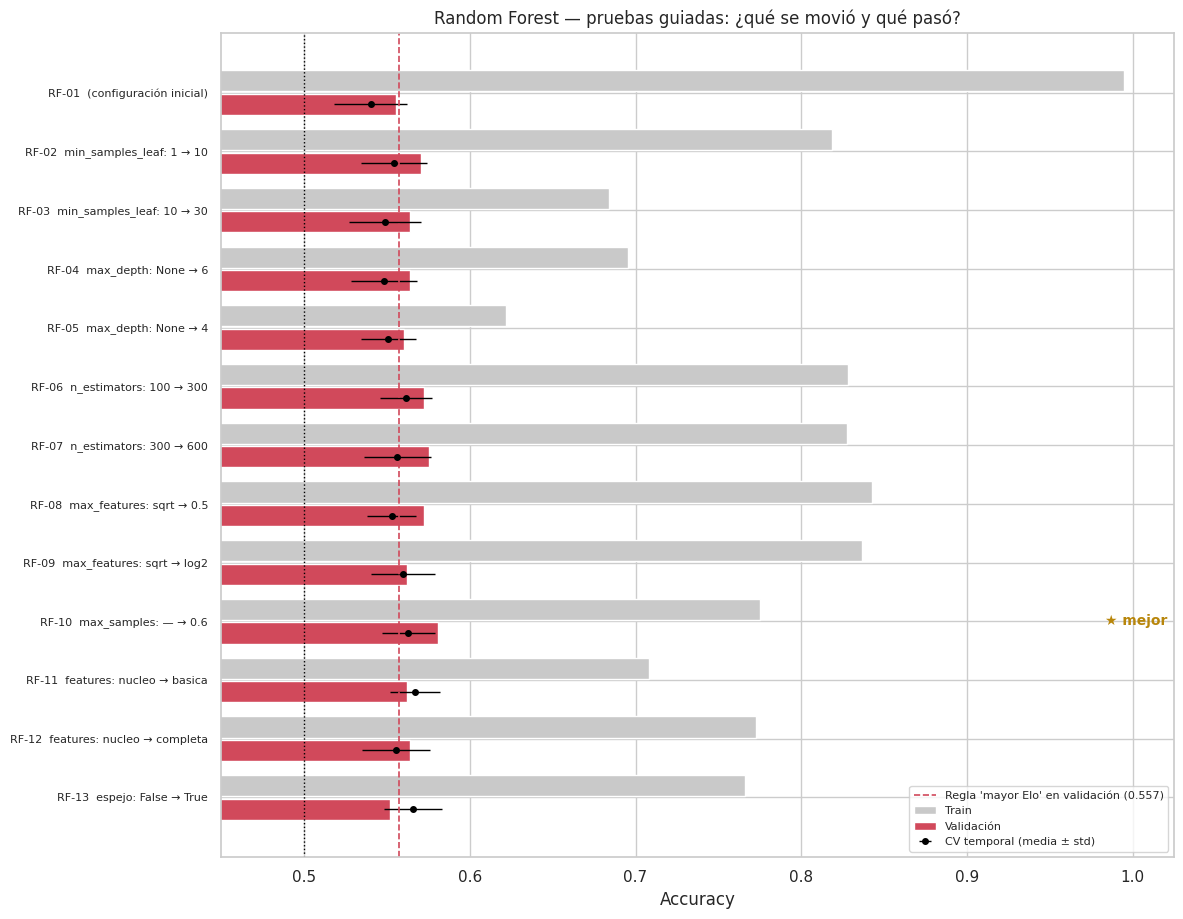

Random Forest: 13 pruebas guiadas.
  Base      RF-01: val 0.555 | cv 0.540 | score 0.5477 | gap train-val +0.440
  Mejor     RF-10: val 0.581 | cv 0.563 | score 0.5717 | gap train-val +0.195
  Mejora del score vs la base: +0.0240
  Configuración: {"features": "nucleo", "n_estimators": 300, "max_depth": null, "min_samples_leaf": 10, "max_features": "sqrt", "espejo": false, "max_samples": 0.6}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas de RF
display(tabla_modelo("RF"))
grafica_pruebas("RF")
resumen_modelo("RF")

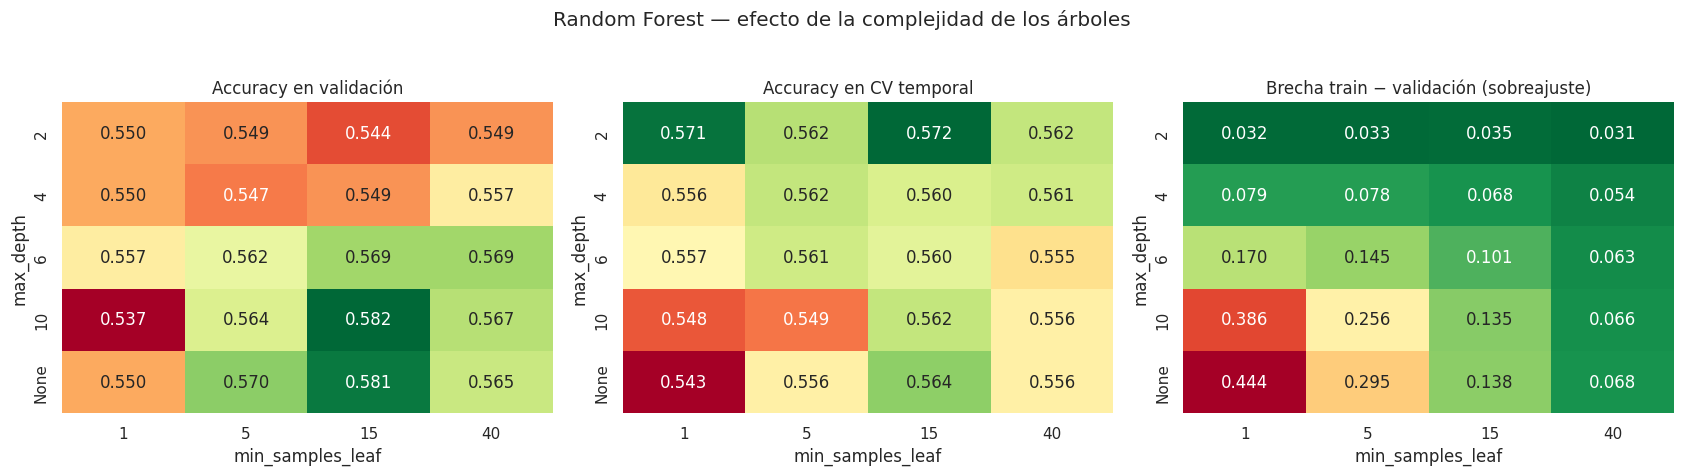

In [ ]:
#@title **BARRIDO RF:** cuadrícula `max_depth` × `min_samples_leaf` (200 árboles, 20 combinaciones registradas)
for md_ in [2, 4, 6, 10, None]:
    for msl in [1, 5, 15, 40]:
        prueba("RF", dict(max_depth=md_, min_samples_leaf=msl, n_estimators=200),
               f"Barrido: max_depth={md_}, min_samples_leaf={msl}, n_estimators=200", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "RF") & (r.tipo == "barrido")].copy()
b["max_depth"] = b["params"].apply(lambda s: str(json.loads(s)["max_depth"])); b["min_samples_leaf"] = b["params"].apply(lambda s: json.loads(s)["min_samples_leaf"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, tit in zip(axes, ["val_acc", "cv_acc", "gap"], ["Accuracy en validación", "Accuracy en CV temporal", "Brecha train − validación (sobreajuste)"]):
    pv = b.pivot(index="max_depth", columns="min_samples_leaf", values=col).reindex(["2", "4", "6", "10", "None"])
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="RdYlGn" if col != "gap" else "RdYlGn_r", ax=ax, cbar=False)
    ax.set_title(tit); ax.set_xlabel("min_samples_leaf"); ax.set_ylabel("max_depth")
plt.suptitle("Random Forest — efecto de la complejidad de los árboles", y=1.03); plt.tight_layout(); plt.show()

Mejor RF: RF-32 — {"features": "nucleo", "n_estimators": 200, "max_depth": null, "min_samples_leaf": 15, "max_features": "sqrt", "espejo": false, "max_samples": 0.6}


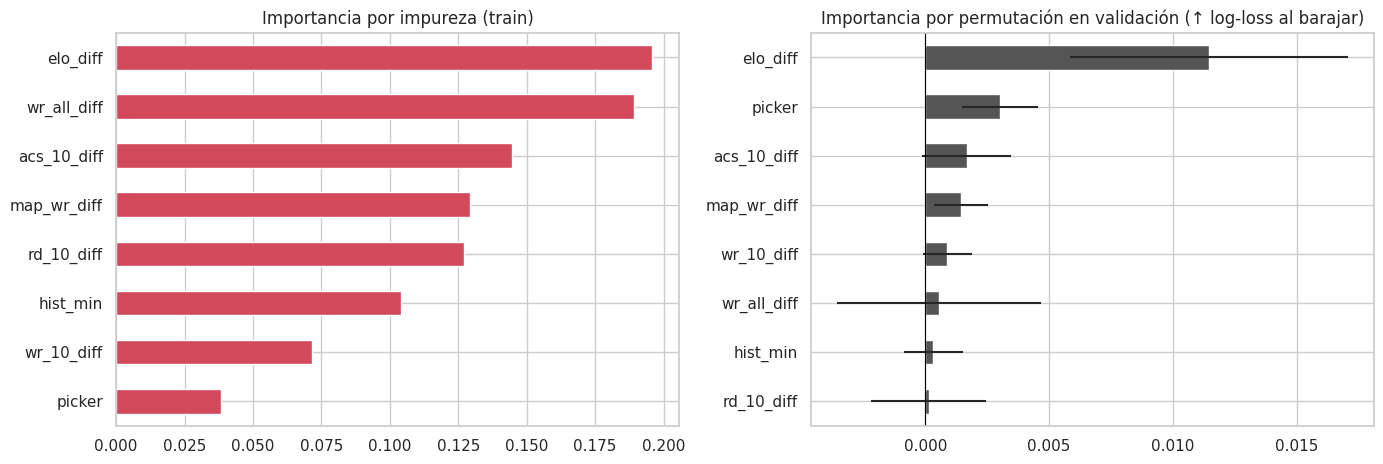

In [ ]:
#@title **GRÁFICA:** importancia de variables del mejor RF (impureza y permutación en validación)
cfg = mejor_global("RF"); est, cols = construir_modelo("RF", cfg["params"]); est.fit(X_tr[cols], y_tr)
print(f"Mejor RF: {cfg['id']} — {json.dumps(cfg['params'], default=str)}")
bosque = desenvolver(est)
imp_gini = pd.Series(bosque.feature_importances_, index=cols).sort_values()
perm = permutation_importance(est, X_va[cols], y_va, scoring="neg_log_loss", n_repeats=20, random_state=SEED)
imp_perm = pd.Series(perm.importances_mean, index=cols)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
imp_gini.tail(12).plot.barh(ax=ax[0], color=COLORES["RF"]); ax[0].set_title("Importancia por impureza (train)")
imp_perm.sort_values().tail(12).plot.barh(ax=ax[1], color="#555555", xerr=pd.Series(perm.importances_std, index=cols).reindex(imp_perm.sort_values().tail(12).index))
ax[1].axvline(0, color="black", lw=.8); ax[1].set_title("Importancia por permutación en validación (↑ log-loss al barajar)")
plt.tight_layout(); plt.show()

### 📖 Lectura de los resultados del Random Forest
- **Línea base:** ≈ 99.5 % en train, ≈ 55.5 % en validación (brecha de 44 puntos). Aun así el bosque generaliza mejor que el árbol solo, porque promedia muchos árboles.
- **Lo que más ayudó:** exigir hojas de ≥ 10 mapas (`min_samples_leaf`), subir a 300 árboles y que cada árbol vea solo el 60 % de los mapas (`max_samples=0.6`). Pasar de 300 a 600 árboles ya no aportó (retornos decrecientes).
- **Lo que no ayudó:** limitar la profundidad, más `max_features`, y **añadir variables** (`completa` empeoró) o quitarlas (`basica`). Más ruido no da más señal.
- **El bosque sigue sobreajustando** (brecha train–validación ≈ 0.14–0.20 incluso en el mejor), pero lo compensa promediando. Obtiene la **mejor accuracy en validación de todos los modelos (≈ 0.58)**; sin embargo su validación cruzada y su test no son mejores (más abajo).
- La cuadrícula `max_depth × min_samples_leaf` muestra una **meseta ancha**: casi todas las casillas rinden entre ≈ 0.54 y 0.58 en validación y entre ≈ 0.54 y 0.57 en CV, señal de que estamos en el techo de lo que estas variables permiten. La zona más "segura" es `max_depth=2` (brecha train–validación ≈ 0.03, CV ≈ 0.57), mientras que la mejor casilla en validación (≈ 0.58) tiene brecha de 0.14.

## 8. Modelo 4 — SVM

Las variables se estandarizan con `Pipeline(StandardScaler → SVC)`, que reajusta el escalado solo con los datos de entrenamiento de cada pliegue (sin fuga). Se activa `probability=True` para obtener probabilidades (necesarias para log-loss, Brier y calibración).

**Hiperparámetros que movemos:**
- `C`: penalización por violar el margen (alto = ajusta más el entrenamiento).
- `gamma` (kernel RBF): alcance de cada observación (alto = frontera muy "nerviosa").
- `kernel`: `rbf`, `linear` o `poly`.
- `class_weight`: pesos por clase.
- `features` y `espejo`.

**Hipótesis central:** hay mucho ruido y señal débil, así que esperamos que **la mejor frontera sea casi lineal** (C pequeño / gamma pequeño o incluso `linear`): fronteras complejas solo memorizarían ruido.

In [ ]:
#@title **EXPERIMENTOS SVM** — cada línea es una prueba registrada
prueba("SVM", params=dict(features="nucleo", kernel="rbf", C=1.0, gamma="scale"),
       hipotesis="Línea base: SVM RBF con C=1 y gamma='scale' (valores por defecto), variables estandarizadas.")

ensayos_svm = [
    (dict(C=0.1),                    "Bajar C a 0.1: tolerar más errores, frontera más suave."),
    (dict(C=0.03),                   "Bajar C a 0.03: regularización aún mayor."),
    (dict(gamma=0.01),               "gamma bajo (0.01): cada observación influye muy lejos → frontera casi lineal."),
    (dict(gamma=0.003),              "gamma muy bajo (0.003)."),
    (dict(kernel="linear"),          "Cambiar a kernel lineal: ¿la frontera curva aporta algo?"),
    (dict(C=0.3),                    "Con el mejor kernel, afinar C hacia arriba (0.3)."),
    (dict(kernel="poly", degree=2),  "Kernel polinómico de grado 2 (interacciones entre variables)."),
    (dict(features="basica"),        "Dar solo 4 variables al SVM."),
    (dict(features="elo"),           "Dar solo el Elo."),
    (dict(features="completa"),      "Dar las 29 variables al SVM."),
    (dict(class_weight="balanced"),  "Pesos balanceados por clase (las clases ya son ~50/50, no debería cambiar mucho)."),
    (dict(espejo=True),              "SVM simétrico: entrenar con el mapa y su versión A↔B."),
]
for cambios, hip in ensayos_svm:
    prueba("SVM", cambios, hip)

[SVM-01] (configuración inicial)                                    | train 0.602  val 0.537  cv 0.528±0.022  logloss 0.687 | base


[SVM-02] C: 1.0 → 0.1                                               | train 0.566  val 0.547  cv 0.529±0.035  logloss 0.683 | ▲ mejora


[SVM-03] C: 0.1 → 0.03                                              | train 0.568  val 0.547  cv 0.528±0.035  logloss 0.685 | ≈ igual


[SVM-04] gamma: scale → 0.01                                        | train 0.560  val 0.550  cv 0.558±0.046  logloss 0.677 | ▲ mejora


[SVM-05] gamma: 0.01 → 0.003                                        | train 0.569  val 0.549  cv 0.554±0.043  logloss 0.680 | ▼ empeora


[SVM-06] kernel: rbf → linear                                       | train 0.562  val 0.562  cv 0.558±0.023  logloss 0.674 | ▲ mejora


... (3 outputs left out)

[SVM-10] features: nucleo → elo                                     | train 0.578  val 0.559  cv 0.570±0.043  logloss 0.676 | ≈ igual


[SVM-11] features: elo → completa                                   | train 0.590  val 0.560  cv 0.549±0.023  logloss 0.676 | ▼ empeora


[SVM-12] class_weight: — → balanced                                 | train 0.575  val 0.557  cv 0.568±0.046  logloss 0.676 | ≈ igual


[SVM-13] espejo: — → True                                           | train 0.571  val 0.555  cv 0.556±0.064  logloss 0.676 | ▼ empeora


,id,referencia,cambió,train_acc,val_acc,cv_acc,cv_std,val_ll,gap,score_sel,veredicto
0,SVM-01,—,(configuración inicial),0.6022,0.5369,0.5279,0.0218,0.6868,0.0653,0.5324,base
1,SVM-02,SVM-01,C: 1.0 → 0.1,0.5664,0.5470,0.5293,0.0351,0.6831,0.0194,0.5381,▲ mejora
2,SVM-03,SVM-02,C: 0.1 → 0.03,0.5681,0.5470,0.5279,0.0346,0.6846,0.0211,0.5375,≈ igual
3,SVM-04,SVM-02,gamma: scale → 0.01,0.5602,0.5503,0.5582,0.0457,0.6768,0.0099,0.5543,▲ mejora
4,SVM-05,SVM-04,gamma: 0.01 → 0.003,0.5686,0.5487,0.5535,0.0431,0.6798,0.0200,0.5511,▼ empeora
5,SVM-06,SVM-04,kernel: rbf → linear,0.5625,0.5621,0.5576,0.0228,0.6738,0.0004,0.5598,▲ mejora
6,SVM-07,SVM-06,C: 0.1 → 0.3,0.5608,0.5621,0.5630,0.0151,0.6738,-0.0013,0.5625,≈ igual
7,SVM-08,SVM-07,kernel: linear → poly | degree: — → 2,0.5143,0.5168,0.4902,0.0281,0.6959,-0.0025,0.5035,▼ empeora
8,SVM-09,SVM-07,features: nucleo → basica,0.5692,0.5587,0.5508,0.0428,0.6744,0.0105,0.5548,▼ empeora
9,SVM-10,SVM-07,features: nucleo → elo,0.5776,0.5587,0.5704,0.0427,0.6757,0.0189,0.5645,≈ igual


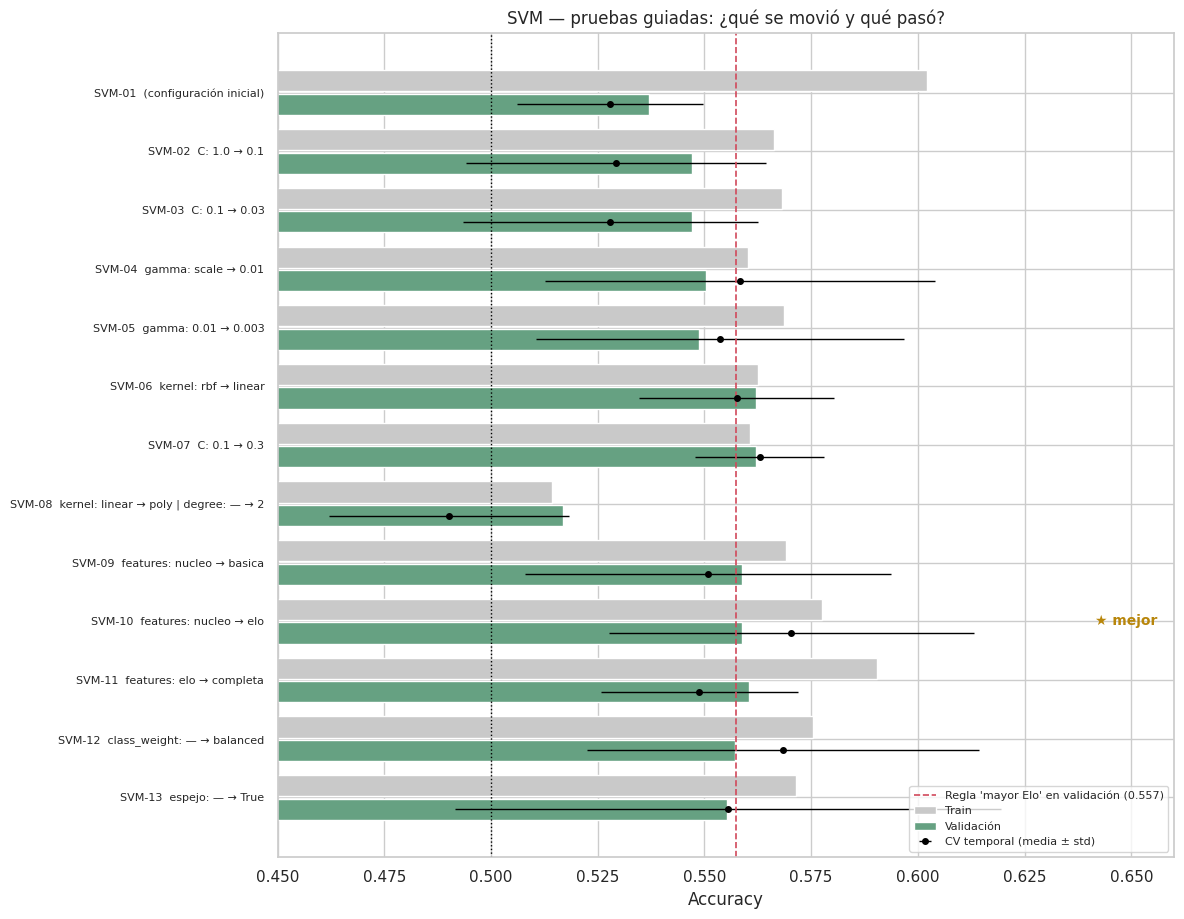

SVM: 13 pruebas guiadas.
  Base      SVM-01: val 0.537 | cv 0.528 | score 0.5324 | gap train-val +0.065
  Mejor     SVM-10: val 0.559 | cv 0.570 | score 0.5645 | gap train-val +0.019
  Mejora del score vs la base: +0.0321
  Configuración: {"features": "elo", "kernel": "linear", "C": 0.3, "gamma": 0.01}


In [ ]:
#@title **TABLA Y GRÁFICA** de las pruebas guiadas de SVM
display(tabla_modelo("SVM"))
grafica_pruebas("SVM")
resumen_modelo("SVM")

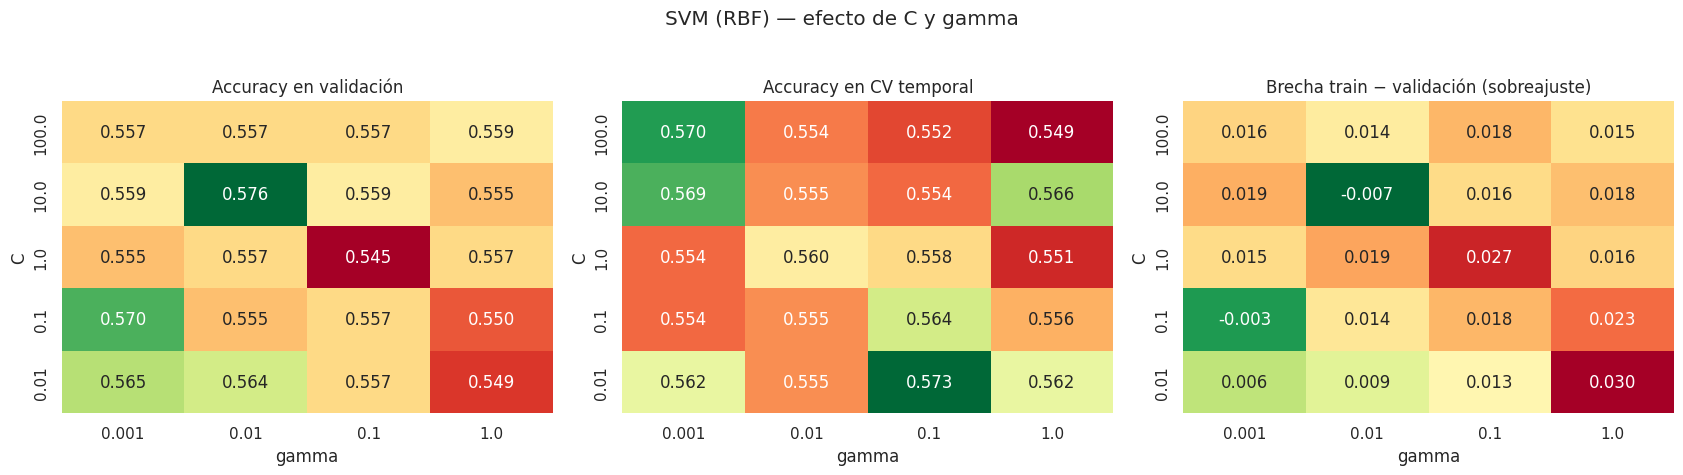

In [ ]:
#@title **BARRIDO SVM:** cuadrícula `C` × `gamma` con kernel RBF (20 combinaciones registradas)
for C in [0.01, 0.1, 1, 10, 100]:
    for g in [0.001, 0.01, 0.1, 1]:
        prueba("SVM", dict(kernel="rbf", C=C, gamma=g), f"Barrido RBF: C={C}, gamma={g}", tipo="barrido", verbose=False)

r = registro_df(); b = r[(r.modelo == "SVM") & (r.tipo == "barrido")].copy()
b["C"] = b["params"].apply(lambda s: json.loads(s)["C"]); b["gamma"] = b["params"].apply(lambda s: json.loads(s)["gamma"])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, col, tit in zip(axes, ["val_acc", "cv_acc", "gap"], ["Accuracy en validación", "Accuracy en CV temporal", "Brecha train − validación (sobreajuste)"]):
    pv = b.pivot(index="C", columns="gamma", values=col).sort_index(ascending=False)
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="RdYlGn" if col != "gap" else "RdYlGn_r", ax=ax, cbar=False)
    ax.set_title(tit); ax.set_xlabel("gamma"); ax.set_ylabel("C")
plt.suptitle("SVM (RBF) — efecto de C y gamma", y=1.03); plt.tight_layout(); plt.show()

### 📖 Lectura de los resultados del SVM
- **Peor arranque** (RBF, C=1): ≈ 0.54 en validación y ≈ 0.53 en CV; la frontera curva se ajusta a ruido.
- **Bajar `C` y `gamma`** (frontera más suave) mejoró, y **cambiar a kernel lineal** dejó la brecha train–validación en ≈ 0 (cero sobreajuste). Se confirma la hipótesis: la mejor frontera es prácticamente una recta.
- **El kernel polinómico de grado 2 se desplomó** (≈ 0.52 en validación, ≈ 0.49 en CV): sin señal que modelar, las interacciones solo inventan estructura.
- Usar solo `elo_diff` fue lo mejor en CV; `class_weight='balanced'` y `espejo` no cambiaron nada relevante.
- Ojo con la **desviación estándar en CV (≈ 0.04–0.06)** de varias pruebas del SVM: es grande, así que varias "mejoras" de ±1 punto son ruido.
- El barrido `C × gamma` se hizo sobre la mejor configuración guiada (que usa solo `elo_diff`): da valores entre ≈ 0.545 y 0.576 **sin un patrón claro y sin sobreajuste** (brecha ≤ 0.03 en todas las casillas). Con una sola variable la frontera es un simple umbral, así que `C` y `gamma` casi no importan; la "mejor" casilla (C=10, gamma=0.01) no se distingue del resto.

## 9. Registro completo de pruebas

Aquí está **todo lo que se probó**: cada fila es un experimento con lo que se movió, la hipótesis, los hiperparámetros completos y las métricas. Se guarda en `registro_pruebas_VCT.csv` (en Colab: panel de archivos de la izquierda, y se descarga automáticamente al final de la celda).

In [ ]:
#@title **CODE:** guardar y mostrar el registro completo
registro = registro_df()
registro.to_csv("registro_pruebas_VCT.csv", index=False, encoding="utf-8-sig")
print(f"✔ {len(registro)} pruebas guardadas en registro_pruebas_VCT.csv")
display(registro.groupby(["modelo", "tipo"]).size().unstack(fill_value=0).rename(columns={"guiada": "pruebas guiadas", "barrido": "pruebas de barrido"}))

print("\nPRUEBAS GUIADAS (en el orden en que se hicieron) — qué se movió y qué pasó:")
display(registro[registro.tipo == "guiada"][["id", "cambió", "val_acc", "cv_acc", "val_ll", "gap", "score_sel", "veredicto"]].round(4).reset_index(drop=True))

print("\nTOP 10 de todas las pruebas por puntaje de selección:")
display(registro.sort_values(["score_sel", "val_ll"], ascending=[False, True]).head(10)[["id", "tipo", "cambió", "val_acc", "cv_acc", "val_ll", "gap", "score_sel"]].round(4).reset_index(drop=True))

try:
    from google.colab import files; files.download("registro_pruebas_VCT.csv")
except Exception:
    pass

✔ 110 pruebas guardadas en registro_pruebas_VCT.csv


tipo,pruebas de barrido,pruebas guiadas
modelo,,
DT,13,12
GNB,10,9
RF,20,13
SVM,20,13



PRUEBAS GUIADAS (en el orden en que se hicieron) — qué se movió y qué pasó:


,id,cambió,val_acc,cv_acc,val_ll,gap,score_sel,veredicto
0,GNB-01,(configuración inicial),0.5520,0.5623,0.9197,0.0228,0.5572,base
1,GNB-02,features: completa → nucleo,0.5537,0.5764,0.7979,0.0138,0.5651,▲ mejora
2,GNB-03,features: nucleo → basica,0.5537,0.5771,0.7109,0.0116,0.5654,≈ igual
3,GNB-04,features: basica → elo,0.5554,0.5919,0.6773,0.0144,0.5736,▲ mejora
4,GNB-05,var_smoothing: 1e-09 → 1e-06,0.5554,0.5919,0.6773,0.0144,0.5736,≈ igual
5,GNB-06,var_smoothing: 1e-09 → 0.001,0.5554,0.5919,0.6773,0.0138,0.5736,≈ igual
6,GNB-07,var_smoothing: 1e-09 → 0.1,0.5570,0.5899,0.6761,0.0166,0.5735,≈ igual
7,GNB-08,"priors: — → [0.5, 0.5]",0.5587,0.5818,0.6783,0.0065,0.5703,▼ empeora
8,GNB-09,espejo: False → True,0.5570,0.5825,0.6756,0.0161,0.5698,▼ empeora
9,DT-01,(configuración inicial),0.5134,0.4970,6.7223,0.4815,0.5052,base



TOP 10 de todas las pruebas por puntaje de selección:


,id,tipo,cambió,val_acc,cv_acc,val_ll,gap,score_sel
0,GNB-17,barrido,var_smoothing: 1e-09 → 0.01,0.5554,0.5919,0.6772,0.0144,0.5736
1,GNB-06,guiada,var_smoothing: 1e-09 → 0.001,0.5554,0.5919,0.6773,0.0138,0.5736
2,GNB-16,barrido,var_smoothing: 1e-09 → 0.001,0.5554,0.5919,0.6773,0.0138,0.5736
3,GNB-15,barrido,var_smoothing: 1e-09 → 0.0001,0.5554,0.5919,0.6773,0.0144,0.5736
4,GNB-14,barrido,var_smoothing: 1e-09 → 9.999999999999999e-06,0.5554,0.5919,0.6773,0.0144,0.5736
5,GNB-05,guiada,var_smoothing: 1e-09 → 1e-06,0.5554,0.5919,0.6773,0.0144,0.5736
6,GNB-13,barrido,var_smoothing: 1e-09 → 1e-06,0.5554,0.5919,0.6773,0.0144,0.5736
7,GNB-12,barrido,var_smoothing: 1e-09 → 1e-07,0.5554,0.5919,0.6773,0.0144,0.5736
8,GNB-11,barrido,var_smoothing: 1e-09 → 1e-08,0.5554,0.5919,0.6773,0.0144,0.5736
9,GNB-04,guiada,features: basica → elo,0.5554,0.5919,0.6773,0.0144,0.5736


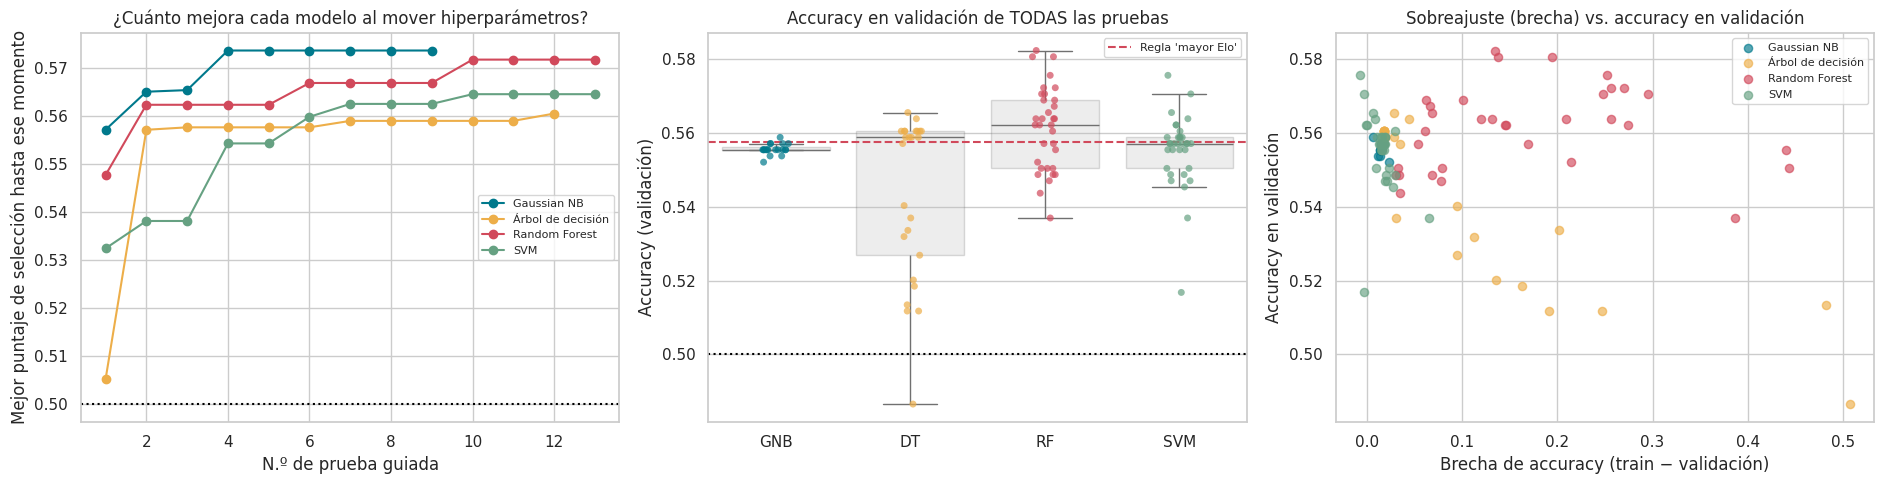

veredicto,base,≈ igual,▲ mejora,▼ empeora
modelo,,,,
DT,1,6,1,4
GNB,1,4,2,2
RF,1,1,3,8
SVM,1,4,3,5


In [ ]:
#@title **GRÁFICAS:** panorama de todas las pruebas
registro = registro_df()
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) evolución del mejor puntaje a lo largo de las pruebas guiadas
for m in NOMBRES:
    g = registro[(registro.modelo == m) & (registro.tipo == "guiada")].reset_index(drop=True)
    axes[0].plot(range(1, len(g) + 1), g.score_sel.cummax(), "o-", color=COLORES[m], label=NOMBRES[m])
axes[0].axhline(0.5, color="black", ls=":"); axes[0].set_xlabel("N.º de prueba guiada"); axes[0].set_ylabel("Mejor puntaje de selección hasta ese momento")
axes[0].set_title("¿Cuánto mejora cada modelo al mover hiperparámetros?"); axes[0].legend(fontsize=8)

# (2) todas las pruebas: accuracy en validación según el modelo
sns.stripplot(data=registro, x="modelo", y="val_acc", hue="modelo", palette=COLORES, order=list(NOMBRES), size=5, alpha=.7, ax=axes[1], legend=False)
sns.boxplot(data=registro, x="modelo", y="val_acc", order=list(NOMBRES), showfliers=False, boxprops=dict(alpha=.25), ax=axes[1], color="#bbbbbb")
axes[1].axhline(ACC_ELO_VAL, color="#d1495b", ls="--", label="Regla 'mayor Elo'"); axes[1].axhline(0.5, color="black", ls=":")
axes[1].set_title("Accuracy en validación de TODAS las pruebas"); axes[1].set_xlabel(""); axes[1].set_ylabel("Accuracy (validación)"); axes[1].legend(fontsize=8)

# (3) mapa de sobreajuste: brecha train-validación vs accuracy en validación
for m in NOMBRES:
    g = registro[registro.modelo == m]; axes[2].scatter(g.gap, g.val_acc, color=COLORES[m], alpha=.65, label=NOMBRES[m], s=35)
axes[2].set_xlabel("Brecha de accuracy (train − validación)"); axes[2].set_ylabel("Accuracy en validación")
axes[2].set_title("Sobreajuste (brecha) vs. accuracy en validación"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

veredictos = registro[registro.tipo == "guiada"].groupby(["modelo", "veredicto"]).size().unstack(fill_value=0)
display(veredictos)

## 10. Comparación final y elección del mejor modelo

**Procedimiento (importante para ser honestos con los resultados):**

1. De cada modelo tomamos **su mejor configuración** según el puntaje de selección (validación + CV temporal). *Todavía no hemos visto el test.*
2. **El modelo ganador se decide con ese puntaje**, antes de mirar 2026.
3. Recién entonces reentrenamos las cuatro configuraciones con **train + validación** (todo 2024–2025) y las evaluamos **una sola vez** en 2026. El test sirve para **confirmar** (¿la elección generaliza al futuro?), no para elegir.
4. Para ver si el ajuste de hiperparámetros realmente sirvió, mostramos también cada modelo **con sus valores por defecto** (la primera prueba de cada uno).

In [ ]:
#@title **CODE:** mejor configuración de cada modelo y decisión (solo con validación + CV)
mejores = {m: mejor_global(m) for m in NOMBRES}
sel = pd.DataFrame([{"Modelo": NOMBRES[m], "Prueba": c["id"], "Tipo": c["tipo"], "val acc": c["val_acc"], "CV acc": c["cv_acc"], "CV std": c["cv_std"],
                     "val AUC": c["val_auc"], "val log-loss": c["val_ll"], "val Brier": c["val_brier"], "gap train-val": c["gap"], "puntaje": c["score_sel"]}
                    for m, c in mejores.items()]).set_index("Modelo")
display(sel.round(4))
GANADOR = min(mejores, key=lambda m: (-round(mejores[m]["score_sel"], 6), mejores[m]["val_ll"]))
print(f"\n🏆 Ganador por puntaje de selección (ANTES de ver el test): {NOMBRES[GANADOR]}  [{mejores[GANADOR]['id']}]")
for m, c in mejores.items():
    print(f"   {NOMBRES[m]:18s} -> {json.dumps(c['params'], default=str)}")

,Prueba,Tipo,val acc,CV acc,CV std,val AUC,val log-loss,val Brier,gap train-val,puntaje
Modelo,,,,,,,,,,
Gaussian NB,GNB-17,barrido,0.5554,0.5919,0.0174,0.5987,0.6772,0.2422,0.0144,0.5736
Árbol de decisión,DT-13,barrido,0.5587,0.5670,0.0217,0.5666,0.6848,0.2459,0.0189,0.5629
Random Forest,RF-32,barrido,0.5805,0.5643,0.0154,0.5955,0.6789,0.2430,0.1377,0.5724
SVM,SVM-27,barrido,0.5755,0.5549,0.0638,0.5999,0.6746,0.2411,-0.0069,0.5652



🏆 Ganador por puntaje de selección (ANTES de ver el test): Gaussian NB  [GNB-17]
   Gaussian NB        -> {"features": "elo", "var_smoothing": 0.01, "espejo": false}
   Árbol de decisión  -> {"features": "nucleo", "criterion": "entropy", "max_depth": 1, "min_samples_leaf": 1, "max_features": null, "ccp_alpha": 0.0, "espejo": true}
   Random Forest      -> {"features": "nucleo", "n_estimators": 200, "max_depth": null, "min_samples_leaf": 15, "max_features": "sqrt", "espejo": false, "max_samples": 0.6}
   SVM                -> {"features": "elo", "kernel": "rbf", "C": 10, "gamma": 0.01}


In [ ]:
#@title **CODE:** classification report en validación de cada mejor modelo
for m, c in mejores.items():
    est, cols = construir_modelo(m, c["params"]); est.fit(X_tr[cols], y_tr)
    pv = proba(est, X_va[cols])
    print(f"=== {NOMBRES[m]} ({c['id']}) — validación ===")
    print(classification_report(y_va, (pv >= 0.5).astype(int), target_names=["Gana B (0)", "Gana A (1)"], digits=3, zero_division=0))

=== Gaussian NB (GNB-17) — validación ===
              precision    recall  f1-score   support

  Gana B (0)      0.539     0.571     0.555       289
  Gana A (1)      0.572     0.541     0.556       307

    accuracy                          0.555       596
   macro avg      0.556     0.556     0.555       596
weighted avg      0.556     0.555     0.555       596

=== Árbol de decisión (DT-13) — validación ===
              precision    recall  f1-score   support

  Gana B (0)      0.550     0.491     0.519       289
  Gana A (1)      0.565     0.622     0.592       307

    accuracy                          0.559       596
   macro avg      0.558     0.557     0.556       596
weighted avg      0.558     0.559     0.557       596



=== Random Forest (RF-32) — validación ===
              precision    recall  f1-score   support

  Gana B (0)      0.564     0.592     0.578       289
  Gana A (1)      0.597     0.570     0.583       307

    accuracy                          0.581       596
   macro avg      0.581     0.581     0.581       596
weighted avg      0.581     0.581     0.581       596



=== SVM (SVM-27) — validación ===
              precision    recall  f1-score   support

  Gana B (0)      0.576     0.474     0.520       289
  Gana A (1)      0.575     0.671     0.620       307

    accuracy                          0.576       596
   macro avg      0.576     0.573     0.570       596
weighted avg      0.576     0.576     0.571       596



In [ ]:
#@title **CODE:** reentrenar con 2024-2025 y evaluar UNA vez en 2026 (modelos afinados vs. valores por defecto)
def ajustar_dev_y_predecir(modelo, params):
    est, cols = construir_modelo(modelo, params); est.fit(X_dev[cols], y_dev)
    return est, proba(est, X_te[cols])

def ic_bootstrap(y_true, p, B=2000, alpha=0.05):
    rng = np.random.default_rng(SEED); yt = np.asarray(y_true); yp = (p >= 0.5).astype(int); n = len(yt)
    idx = rng.integers(0, n, size=(B, n)); accs = (yt[idx] == yp[idx]).mean(axis=1)
    return np.quantile(accs, [alpha / 2, 1 - alpha / 2])

modelos_dev, P_TEST, P_DEF = {}, {}, {}
for m, c in mejores.items():
    modelos_dev[m], P_TEST[m] = ajustar_dev_y_predecir(m, c["params"])
    base0 = [r for r in REGISTRO if r["modelo"] == m][0]
    _, P_DEF[m] = ajustar_dev_y_predecir(m, base0["params"])

filas = []
for m in NOMBRES:
    for etiqueta, P in [("afinado", P_TEST[m]), ("por defecto", P_DEF[m])]:
        mt = metricas(y_te, P); lo, hi = ic_bootstrap(y_te, P)
        filas.append({"Modelo": NOMBRES[m], "Versión": etiqueta, "accuracy": mt["acc"], "IC95% inf": lo, "IC95% sup": hi, "precision": mt["prec"],
                      "sensibilidad (TPR)": mt["rec"], "especificidad (TNR)": mt["esp"], "F1": mt["f1"], "AUC": mt["auc"], "log-loss": mt["ll"], "Brier": mt["brier"]})
test_tab = pd.DataFrame(filas)
display(test_tab.round(4))

p_elo_te = 1 / (1 + 10 ** (-X_te["elo_diff"].values / 400))
print(f"Referencias en 2026 -> siempre A: {y_te.mean():.3f} | regla 'mayor Elo': {regla(X_te, y_te, 'elo_diff')[0]:.3f} (log-loss del Elo: {log_loss(y_te, np.clip(p_elo_te, 1e-3, 1-1e-3)):.4f}) | azar puro log-loss = {np.log(2):.4f}")

,Modelo,Versión,accuracy,IC95% inf,IC95% sup,precision,sensibilidad (TPR),especificidad (TNR),F1,AUC,log-loss,Brier
0,Gaussian NB,afinado,0.5914,0.5598,0.6219,0.5596,0.6292,0.5577,0.5923,0.6098,0.6782,0.2422
1,Gaussian NB,por defecto,0.5463,0.5147,0.5790,0.5207,0.4809,0.6047,0.5000,0.5884,0.9075,0.3015
2,Árbol de decisión,afinado,0.5835,0.5530,0.6151,0.5505,0.6388,0.5342,0.5914,0.5980,0.6764,0.2417
3,Árbol de decisión,por defecto,0.5045,0.4718,0.5372,0.4766,0.5120,0.4979,0.4937,0.5055,6.8306,0.4946
4,Random Forest,afinado,0.5711,0.5395,0.6027,0.5440,0.5622,0.5791,0.5529,0.6094,0.6766,0.2418
5,Random Forest,por defecto,0.5372,0.5045,0.5700,0.5090,0.5431,0.5321,0.5255,0.5489,0.7002,0.2531
6,SVM,afinado,0.5880,0.5564,0.6185,0.5523,0.6699,0.5150,0.6054,0.6089,0.6779,0.2422
7,SVM,por defecto,0.5688,0.5361,0.6016,0.5386,0.6005,0.5406,0.5679,0.6081,0.6793,0.2431


Referencias en 2026 -> siempre A: 0.472 | regla 'mayor Elo': 0.594 (log-loss del Elo: 0.6795) | azar puro log-loss = 0.6931


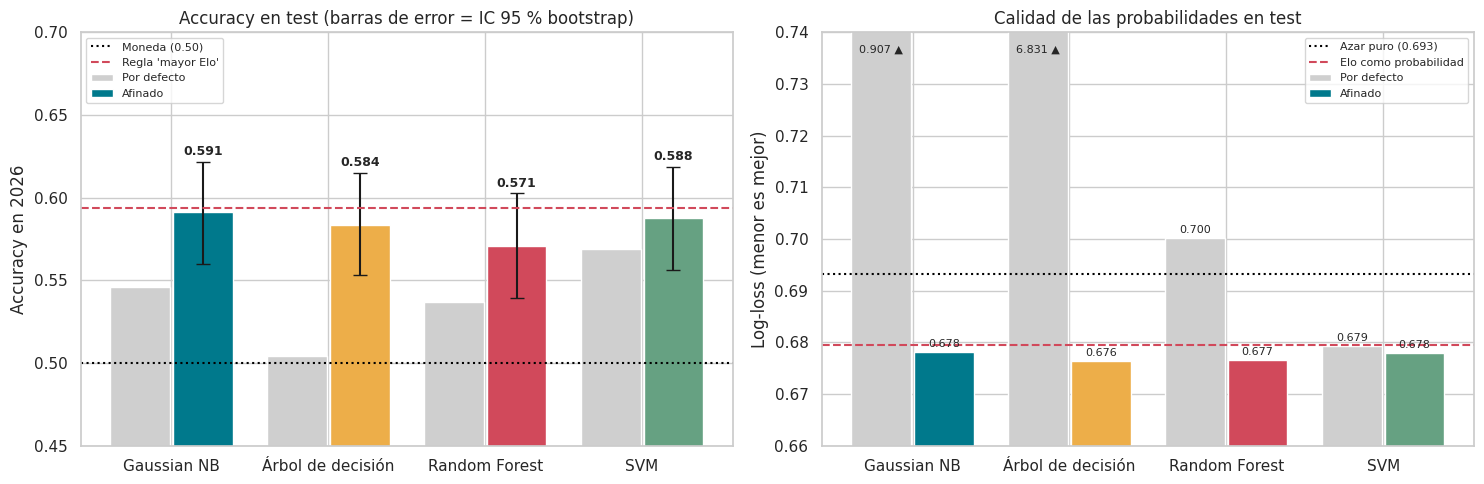

In [ ]:
#@title **GRÁFICA 1:** accuracy (con intervalo de confianza) y log-loss en test 2026
afi = test_tab[test_tab["Versión"] == "afinado"].set_index("Modelo"); dfl = test_tab[test_tab["Versión"] == "por defecto"].set_index("Modelo")
orden = [NOMBRES[m] for m in NOMBRES]; x = np.arange(len(orden)); inv = {v: k for k, v in NOMBRES.items()}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(x - 0.2, dfl.loc[orden, "accuracy"], 0.38, color="#cfcfcf", label="Por defecto")
ax[0].bar(x + 0.2, afi.loc[orden, "accuracy"], 0.38, color=[COLORES[inv[o]] for o in orden], label="Afinado",
          yerr=[afi.loc[orden, "accuracy"] - afi.loc[orden, "IC95% inf"], afi.loc[orden, "IC95% sup"] - afi.loc[orden, "accuracy"]], capsize=5)
for i, o in enumerate(orden): ax[0].text(i + 0.2, afi.loc[o, "IC95% sup"] + 0.004, f"{afi.loc[o, 'accuracy']:.3f}", ha="center", fontsize=9, fontweight="bold")
ax[0].axhline(0.5, color="black", ls=":", label="Moneda (0.50)"); ax[0].axhline(regla(X_te, y_te, "elo_diff")[0], color="#d1495b", ls="--", label="Regla 'mayor Elo'")
ax[0].set_xticks(x); ax[0].set_xticklabels(orden); ax[0].set_ylim(0.45, 0.70); ax[0].set_ylabel("Accuracy en 2026"); ax[0].set_title("Accuracy en test (barras de error = IC 95 % bootstrap)"); ax[0].legend(fontsize=8, loc="upper left")
ax[1].bar(x - 0.2, dfl.loc[orden, "log-loss"], 0.38, color="#cfcfcf", label="Por defecto"); ax[1].bar(x + 0.2, afi.loc[orden, "log-loss"], 0.38, color=[COLORES[inv[o]] for o in orden], label="Afinado")
ax[1].axhline(np.log(2), color="black", ls=":", label="Azar puro (0.693)"); ax[1].axhline(log_loss(y_te, np.clip(p_elo_te, 1e-3, 1-1e-3)), color="#d1495b", ls="--", label="Elo como probabilidad")
ax[1].set_xticks(x); ax[1].set_xticklabels(orden); ax[1].set_ylim(0.66, 0.74); ax[1].set_ylabel("Log-loss (menor es mejor)"); ax[1].set_title("Calidad de las probabilidades en test"); ax[1].legend(fontsize=8, loc="upper right")
for i, o in enumerate(orden):                                   # etiquetas numéricas; las barras fuera de escala se marcan con ▲
    for dx, val in [(-0.2, dfl.loc[o, "log-loss"]), (0.2, afi.loc[o, "log-loss"])]:
        ax[1].text(i + dx, min(val, 0.735) + 0.001, f"{val:.3f}" + (" ▲" if val > 0.74 else ""), ha="center", fontsize=8)
plt.tight_layout(); plt.show()

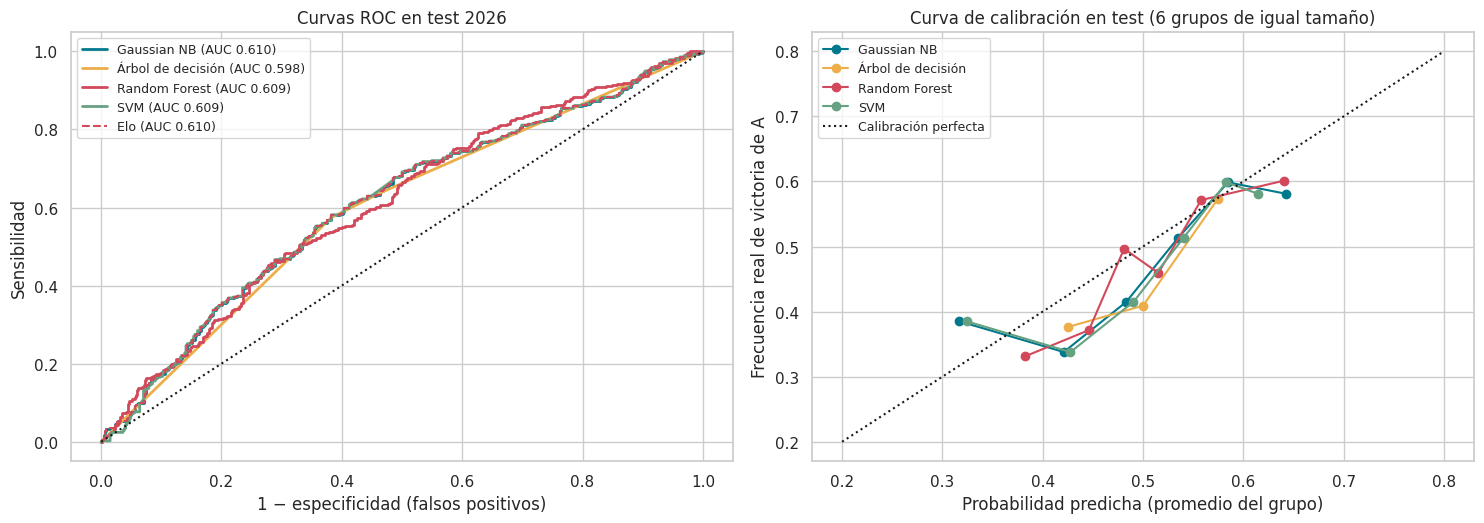

In [ ]:
#@title **GRÁFICA 2:** curvas ROC y calibración (¿las probabilidades son creíbles?)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4))
for m in NOMBRES:
    fpr, tpr_, _ = roc_curve(y_te, P_TEST[m]); ax[0].plot(fpr, tpr_, color=COLORES[m], lw=2, label=f"{NOMBRES[m]} (AUC {roc_auc_score(y_te, P_TEST[m]):.3f})")
fpr, tpr_, _ = roc_curve(y_te, X_te["elo_diff"]); ax[0].plot(fpr, tpr_, color="#d1495b", ls="--", label=f"Elo (AUC {roc_auc_score(y_te, X_te['elo_diff']):.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("1 − especificidad (falsos positivos)"); ax[0].set_ylabel("Sensibilidad"); ax[0].set_title("Curvas ROC en test 2026"); ax[0].legend(fontsize=9)
for m in NOMBRES:
    fo, mp = calibration_curve(y_te, P_TEST[m], n_bins=6, strategy="quantile"); ax[1].plot(mp, fo, "o-", color=COLORES[m], label=NOMBRES[m])
ax[1].plot([0.2, 0.8], [0.2, 0.8], "k:", label="Calibración perfecta"); ax[1].set_xlabel("Probabilidad predicha (promedio del grupo)"); ax[1].set_ylabel("Frecuencia real de victoria de A")
ax[1].set_title("Curva de calibración en test (6 grupos de igual tamaño)"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

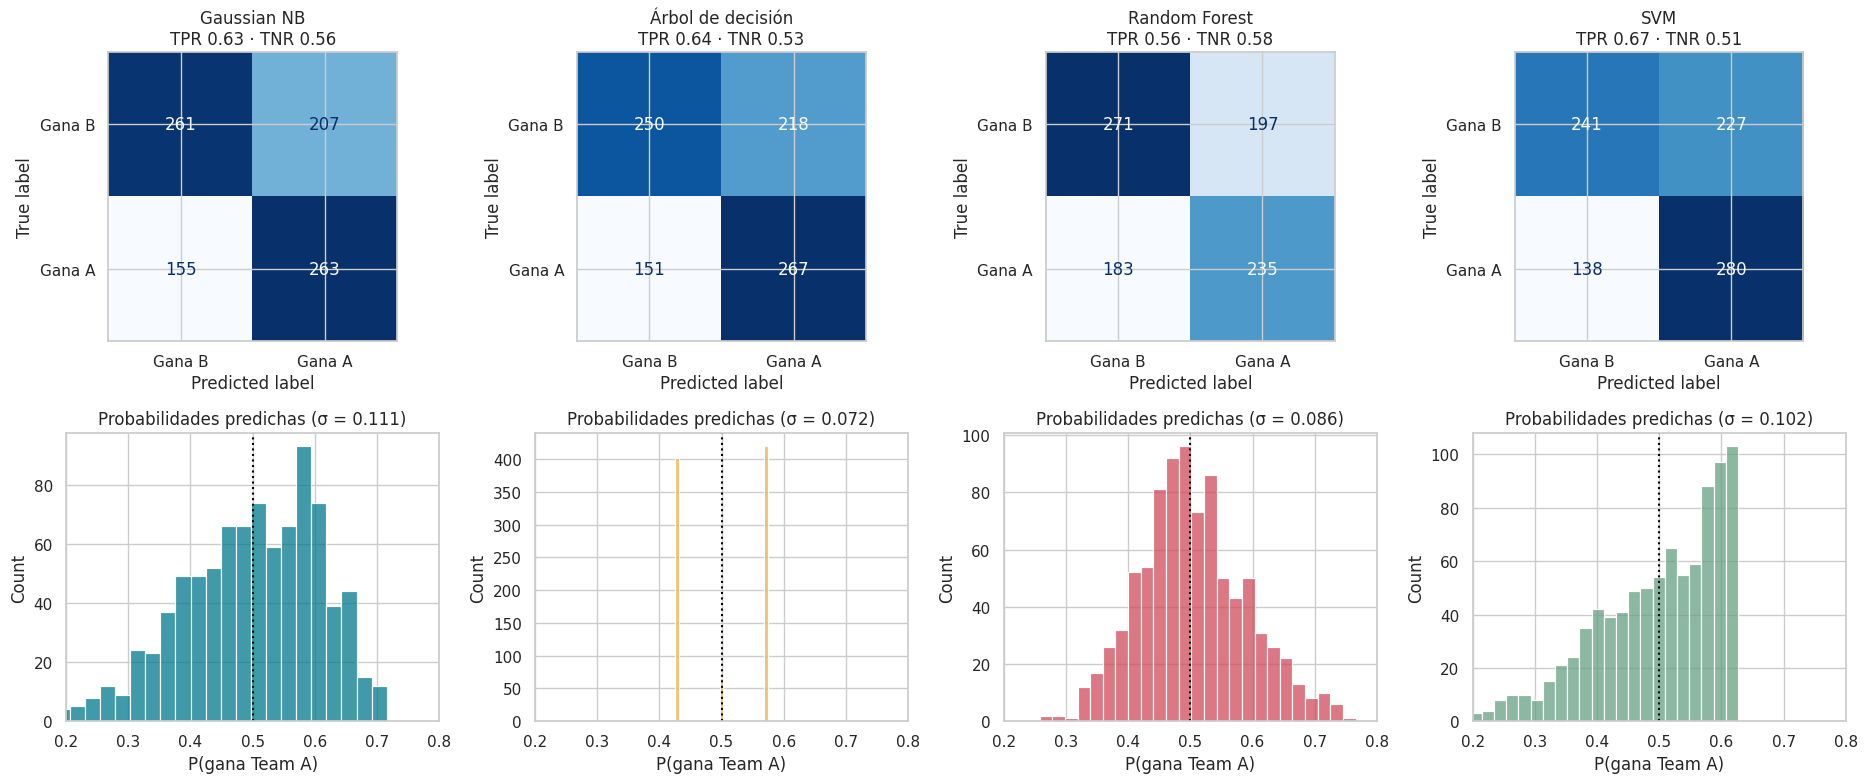

In [ ]:
#@title **GRÁFICA 3:** matrices de confusión e histograma de probabilidades predichas
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for j, m in enumerate(NOMBRES):
    cm = confusion_matrix(y_te, (P_TEST[m] >= 0.5).astype(int), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Gana B", "Gana A"]).plot(ax=axes[0, j], cmap="Blues", colorbar=False)
    tn, fp, fn, tp = cm.ravel(); axes[0, j].set_title(f"{NOMBRES[m]}\nTPR {tp/(tp+fn):.2f} · TNR {tn/(tn+fp):.2f}")
    sns.histplot(P_TEST[m], bins=25, color=COLORES[m], ax=axes[1, j]); axes[1, j].axvline(0.5, color="black", ls=":")
    axes[1, j].set_xlim(0.2, 0.8); axes[1, j].set_xlabel("P(gana Team A)"); axes[1, j].set_title(f"Probabilidades predichas (σ = {P_TEST[m].std():.3f})")
plt.tight_layout(); plt.show()

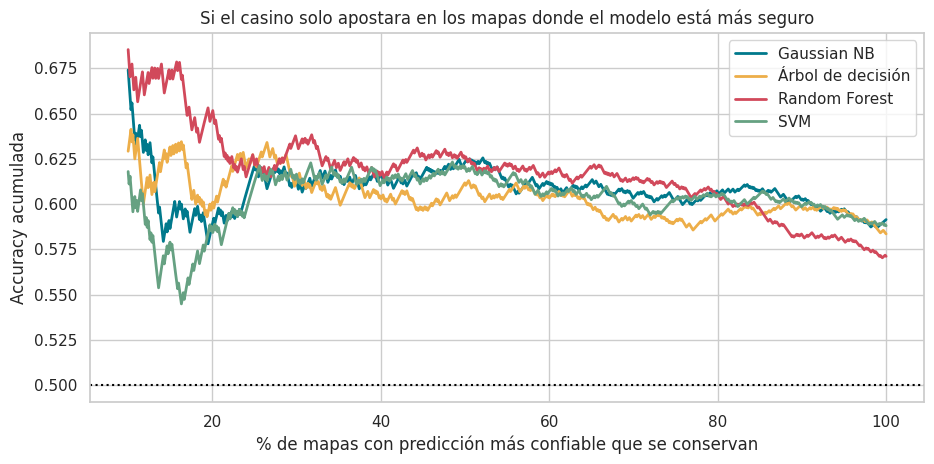

In [ ]:
#@title **GRÁFICA 4:** ¿acierta más cuando está más seguro?  (accuracy acumulada según la confianza)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for m in NOMBRES:
    conf = np.abs(P_TEST[m] - 0.5); orden_c = np.argsort(-conf); acierto = ((P_TEST[m] >= 0.5).astype(int) == y_te.values)[orden_c]
    cubre = np.arange(1, len(acierto) + 1) / len(acierto); acc_acum = np.cumsum(acierto) / np.arange(1, len(acierto) + 1)
    sel_ = cubre >= 0.1; ax.plot(cubre[sel_] * 100, acc_acum[sel_], color=COLORES[m], lw=2, label=NOMBRES[m])
ax.axhline(0.5, color="black", ls=":"); ax.set_xlabel("% de mapas con predicción más confiable que se conservan"); ax.set_ylabel("Accuracy acumulada")
ax.set_title("Si el casino solo apostara en los mapas donde el modelo está más seguro"); ax.legend(); plt.tight_layout(); plt.show()

In [ ]:
#@title **CODE:** ¿la diferencia entre el ganador y el segundo es real? (prueba de McNemar exacta)
orden_acc = sorted(NOMBRES, key=lambda m: -accuracy_score(y_te, P_TEST[m] >= 0.5))
print("Ranking por accuracy en test:", " > ".join(f"{NOMBRES[m]} ({accuracy_score(y_te, P_TEST[m] >= 0.5):.3f})" for m in orden_acc))

def mcnemar_exacto(y_true, p1, p2):
    a = ((p1 >= .5).astype(int) == y_true.values); b = ((p2 >= .5).astype(int) == y_true.values)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    pval = stats.binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, pval

rival = [m for m in orden_acc if m != GANADOR][0]
n10, n01, pv = mcnemar_exacto(y_te, P_TEST[GANADOR], P_TEST[rival])
print(f"\nGanador ({NOMBRES[GANADOR]}) vs {NOMBRES[rival]}: acierta solo el ganador en {n10} mapas, solo el rival en {n01}; p-valor McNemar = {pv:.3f}")
print("→", "diferencia estadísticamente significativa (p < 0.05)" if pv < 0.05 else "NO hay evidencia de que uno sea mejor que el otro (p ≥ 0.05): con ~900 mapas, diferencias de 1-3 puntos son compatibles con el azar.")

Ranking por accuracy en test: Gaussian NB (0.591) > SVM (0.588) > Árbol de decisión (0.584) > Random Forest (0.571)

Ganador (Gaussian NB) vs SVM: acierta solo el ganador en 20 mapas, solo el rival en 17; p-valor McNemar = 0.743
→ NO hay evidencia de que uno sea mejor que el otro (p ≥ 0.05): con ~900 mapas, diferencias de 1-3 puntos son compatibles con el azar.


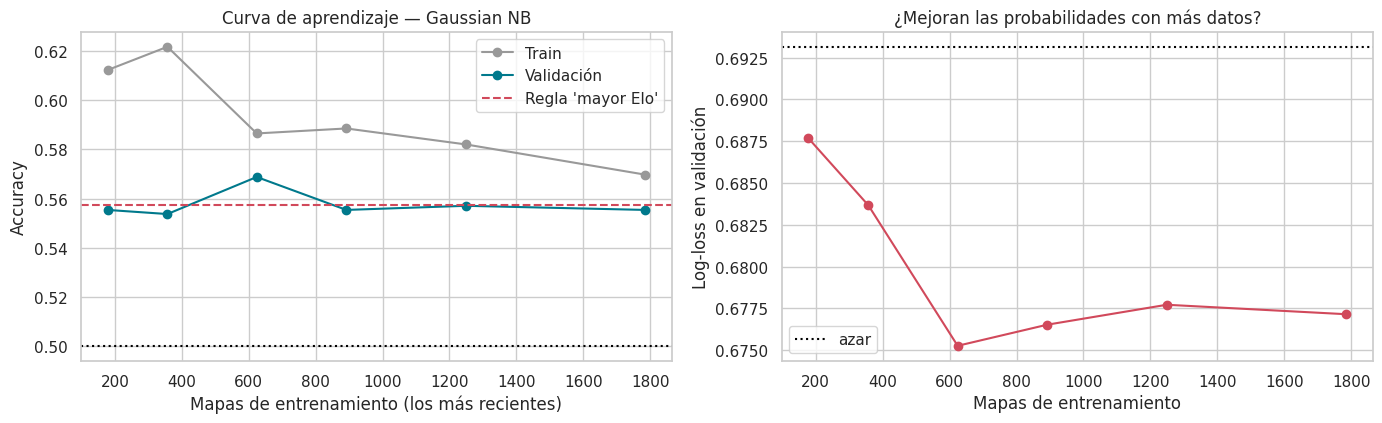

In [ ]:
#@title **GRÁFICA 5:** curva de aprendizaje del modelo ganador (¿más datos ayudarían?)
cfg = mejores[GANADOR]; fr = [0.1, 0.2, 0.35, 0.5, 0.7, 1.0]; filas = []
for f in fr:
    k = max(int(len(X_tr) * f), 60); est, cols = construir_modelo(GANADOR, cfg["params"])
    est.fit(X_tr.iloc[-k:][cols], y_tr.iloc[-k:])                     # los k mapas MÁS RECIENTES del train
    filas.append({"n": k, "train": accuracy_score(y_tr.iloc[-k:], proba(est, X_tr.iloc[-k:][cols]) >= .5),
                  "val": accuracy_score(y_va, proba(est, X_va[cols]) >= .5), "ll": log_loss(y_va, np.clip(proba(est, X_va[cols]), 1e-6, 1-1e-6))})
lc = pd.DataFrame(filas)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(lc.n, lc.train, "o-", color="#999999", label="Train"); ax[0].plot(lc.n, lc.val, "o-", color=COLORES[GANADOR], label="Validación")
ax[0].axhline(ACC_ELO_VAL, color="#d1495b", ls="--", label="Regla 'mayor Elo'"); ax[0].axhline(0.5, color="black", ls=":"); ax[0].set_xlabel("Mapas de entrenamiento (los más recientes)"); ax[0].set_ylabel("Accuracy"); ax[0].legend(); ax[0].set_title(f"Curva de aprendizaje — {NOMBRES[GANADOR]}")
ax[1].plot(lc.n, lc.ll, "o-", color="#d1495b"); ax[1].axhline(np.log(2), color="black", ls=":", label="azar"); ax[1].set_xlabel("Mapas de entrenamiento"); ax[1].set_ylabel("Log-loss en validación"); ax[1].set_title("¿Mejoran las probabilidades con más datos?"); ax[1].legend()
plt.tight_layout(); plt.show()

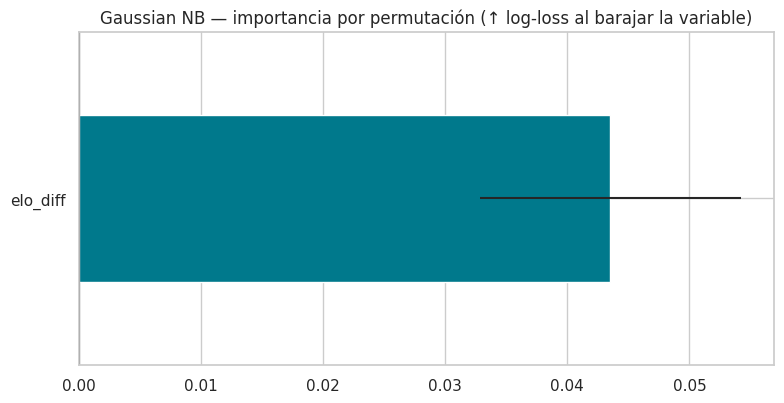

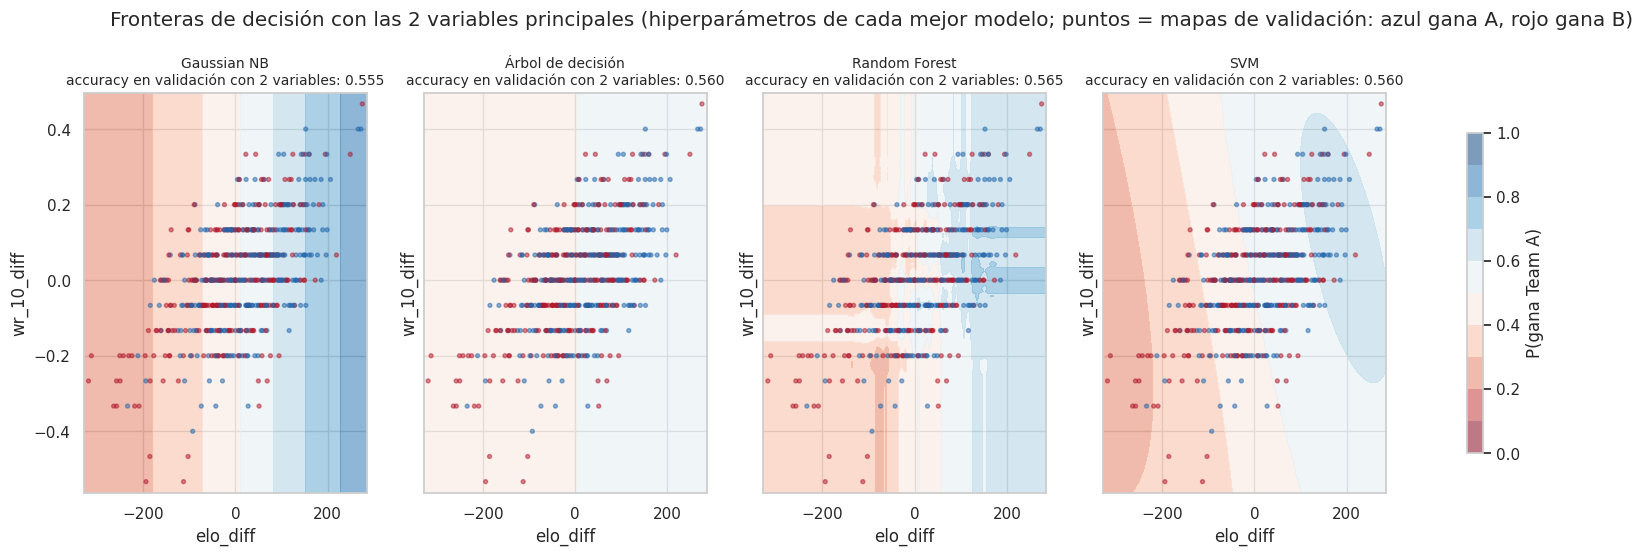

In [ ]:
#@title **GRÁFICA 6:** importancia por permutación del ganador y fronteras de decisión con 2 variables
cfg = mejores[GANADOR]; est, cols = construir_modelo(GANADOR, cfg["params"]); est.fit(X_tr[cols], y_tr)
perm = permutation_importance(est, X_va[cols], y_va, scoring="neg_log_loss", n_repeats=30, random_state=SEED)
pi = pd.Series(perm.importances_mean, index=cols).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2)); pi.plot.barh(ax=ax, color=COLORES[GANADOR], xerr=pd.Series(perm.importances_std, index=cols).reindex(pi.index))
ax.axvline(0, color="black", lw=.8); ax.set_title(f"{NOMBRES[GANADOR]} — importancia por permutación (↑ log-loss al barajar la variable)"); plt.tight_layout(); plt.show()

# Fronteras de decisión con las dos variables más informativas
cols2 = CONJUNTOS["dos_vars"]
lim0, lim1 = (X_va[cols2[0]].min() - 10, X_va[cols2[0]].max() + 10), (X_va[cols2[1]].min() - 0.03, X_va[cols2[1]].max() + 0.03)
gx, gy = np.meshgrid(np.linspace(*lim0, 160), np.linspace(*lim1, 160))
malla = pd.DataFrame({cols2[0]: gx.ravel(), cols2[1]: gy.ravel()})
fig, axes = plt.subplots(1, 4, figsize=(21, 5.2), sharey=True)
for ax, m in zip(axes, NOMBRES):
    p2 = {**mejores[m]["params"], "features": "dos_vars", "espejo": False}
    e2, c2 = construir_modelo(m, p2); e2.fit(X_tr[c2], y_tr)
    zz = proba(e2, malla[c2]).reshape(gx.shape)
    cs = ax.contourf(gx, gy, zz, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=.55)
    ax.scatter(X_va[cols2[0]], X_va[cols2[1]], c=y_va.map({1: "#2166ac", 0: "#b2182b"}), s=8, alpha=.5)
    ax.set_title(f"{NOMBRES[m]}\naccuracy en validación con 2 variables: {accuracy_score(y_va, proba(e2, X_va[c2]) >= .5):.3f}", fontsize=10); ax.set_xlabel(cols2[0]); ax.set_ylabel(cols2[1])
fig.colorbar(cs, ax=axes, shrink=.8, label="P(gana Team A)"); plt.suptitle("Fronteras de decisión con las 2 variables principales (hiperparámetros de cada mejor modelo; puntos = mapas de validación: azul gana A, rojo gana B)", y=1.04); plt.show()

### De probabilidad a cuota: cómo lo usaría el casino
Con la probabilidad del modelo ganador, la **cuota justa** es `1 / probabilidad`. Estos son los primeros mapas de 2026 (el modelo fue entrenado solo con 2024–2025). Además guardamos el modelo ganador en un archivo para reutilizarlo en la siguiente entrega.

In [ ]:
#@title **CODE:** ejemplo de uso del modelo ganador y guardado del modelo
import joblib
cols_g = construir_modelo(GANADOR, mejores[GANADOR]["params"])[1]
modelo_ganador = modelos_dev[GANADOR]                                   # ya reentrenado con 2024-2025
joblib.dump({"modelo": modelo_ganador, "columnas": cols_g, "params": mejores[GANADOR]["params"], "nombre": NOMBRES[GANADOR]}, "modelo_ganador_VCT.joblib")
print(f"✔ Modelo guardado: modelo_ganador_VCT.joblib  ({NOMBRES[GANADOR]}, variables: {cols_g})")

ej = df.iloc[idx_test][["tournament", "team_a", "team_b", "map", "team_a_wins"]].head(10).reset_index(drop=True)
pA = proba(modelo_ganador, X_te[cols_g].head(10))
ej["P(gana A)"] = pA.round(3); ej["cuota A"] = (1 / pA).round(2); ej["cuota B"] = (1 / (1 - pA)).round(2)
ej["favorito"] = np.where(pA >= .5, ej.team_a, ej.team_b); ej["ganó"] = np.where(ej.team_a_wins == 1, ej.team_a, ej.team_b)
ej["¿acertó?"] = np.where(ej.favorito == ej["ganó"], "✔", "✘")
display(ej.drop(columns="team_a_wins"))
try:
    from google.colab import files; files.download("modelo_ganador_VCT.joblib")
except Exception:
    pass

✔ Modelo guardado: modelo_ganador_VCT.joblib  (Gaussian NB, variables: ['elo_diff'])


,tournament,team_a,team_b,map,P(gana A),cuota A,cuota B,favorito,ganó,¿acertó?
0,VCT 2026: EMEA Kickoff,Natus Vincere,Karmine Corp,Split,0.519,1.93,2.08,Natus Vincere,Natus Vincere,✔
1,VCT 2026: EMEA Kickoff,Natus Vincere,Karmine Corp,Haven,0.535,1.87,2.15,Natus Vincere,Natus Vincere,✔
2,VCT 2026: EMEA Kickoff,FUT Esports,Gentle Mates,Abyss,0.585,1.71,2.41,FUT Esports,Gentle Mates,✘
3,VCT 2026: EMEA Kickoff,FUT Esports,Gentle Mates,Split,0.564,1.77,2.30,FUT Esports,Gentle Mates,✘
4,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Breeze,0.453,2.21,1.83,BBL Esports,BBL Esports,✔
5,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Abyss,0.434,2.30,1.77,BBL Esports,PCIFIC Esports,✘
6,VCT 2026: EMEA Kickoff,PCIFIC Esports,BBL Esports,Pearl,0.462,2.16,1.86,BBL Esports,BBL Esports,✔
7,VCT 2026: EMEA Kickoff,ULF Esports,Team Vitality,Breeze,0.513,1.95,2.06,ULF Esports,Team Vitality,✘
8,VCT 2026: EMEA Kickoff,ULF Esports,Team Vitality,Corrode,0.486,2.06,1.95,Team Vitality,Team Vitality,✔
9,VCT 2026: EMEA Kickoff,Team Heretics,Natus Vincere,Bind,0.587,1.70,2.42,Team Heretics,Natus Vincere,✘


## 11. Conclusiones

In [ ]:
#@title **RESUMEN EJECUTIVO** (se genera con los resultados de esta ejecución)
print("=" * 92)
print(f"Se registraron {len(REGISTRO)} pruebas ({sum(r['tipo']=='guiada' for r in REGISTRO)} guiadas + {sum(r['tipo']=='barrido' for r in REGISTRO)} de barrido) sobre los 4 modelos.")
print(f"Protocolo temporal: train {len(y_tr)} | validación {len(y_va)} | test 2026 {len(y_te)} mapas.\n")
print(f"{'Modelo':<20s}{'val acc':>9s}{'CV acc':>9s}{'test acc':>10s}{'IC 95 % test':>18s}{'test AUC':>10s}{'test logloss':>14s}")
for m in NOMBRES:
    t = afi.loc[NOMBRES[m]]; c = mejores[m]
    print(f"{NOMBRES[m]:<20s}{c['val_acc']:>9.3f}{c['cv_acc']:>9.3f}{t['accuracy']:>10.3f}{'['+format(t['IC95% inf'],'.3f')+', '+format(t['IC95% sup'],'.3f')+']':>18s}{t['AUC']:>10.3f}{t['log-loss']:>14.4f}")
print(f"\nModelo elegido ANTES de ver el test: {NOMBRES[GANADOR]}  ->  {json.dumps(mejores[GANADOR]['params'], default=str)}")
mejor_test = max(NOMBRES, key=lambda m: afi.loc[NOMBRES[m], "accuracy"])
print(f"Mejor accuracy en test: {NOMBRES[mejor_test]} ({afi.loc[NOMBRES[mejor_test], 'accuracy']:.3f}).  " + ("La elección hecha con validación se confirma." if mejor_test == GANADOR else "Ojo: el test favorece a otro modelo, pero la diferencia debe leerse junto con los intervalos de confianza."))
print(f"Referencias en 2026: regla 'mayor Elo' = {regla(X_te, y_te, 'elo_diff')[0]:.3f} · siempre A = {y_te.mean():.3f} · línea base de la primera entrega (win rate histórico) = 0.556")
print("=" * 92)

Se registraron 110 pruebas (47 guiadas + 63 de barrido) sobre los 4 modelos.
Protocolo temporal: train 1785 | validación 596 | test 2026 886 mapas.

Modelo                val acc   CV acc  test acc      IC 95 % test  test AUC  test logloss
Gaussian NB             0.555    0.592     0.591    [0.560, 0.622]     0.610        0.6782
Árbol de decisión       0.559    0.567     0.584    [0.553, 0.615]     0.598        0.6764
Random Forest           0.581    0.564     0.571    [0.540, 0.603]     0.609        0.6766
SVM                     0.576    0.555     0.588    [0.556, 0.619]     0.609        0.6779

Modelo elegido ANTES de ver el test: Gaussian NB  ->  {"features": "elo", "var_smoothing": 0.01, "espejo": false}
Mejor accuracy en test: Gaussian NB (0.591).  La elección hecha con validación se confirma.
Referencias en 2026: regla 'mayor Elo' = 0.594 · siempre A = 0.472 · línea base de la primera entrega (win rate histórico) = 0.556


### Qué aprendimos

**1. Modelo elegido: Gaussian Naive Bayes** (variable `elo_diff`, `var_smoothing=0.01`), decidido con validación + CV temporal *antes* de ver el test, y confirmado en 2026 (≈ 59.1 % de accuracy, AUC ≈ 0.61, log-loss ≈ 0.678). Supera con claridad la línea base de la primera entrega (55.6 %) y el azar (log-loss 0.693).

**2. Pero hay que ser honestos con lo que significa.**
- Los cuatro modelos afinados quedan **estadísticamente empatados** en 2026 (≈ 57–59 %; los intervalos de confianza del 95 % se traslapan por completo y McNemar entre el 1.º y el 2.º da p ≈ 0.74). El orden del ranking no es una diferencia real.
- **Ninguno supera la regla simple "gana el de mayor Elo"** (≈ 59.4 % en 2026). Los modelos ganadores terminan siendo, en el fondo, una versión del Elo con probabilidades: sus curvas ROC casi se superponen.
- En validación el Random Forest tuvo la mejor accuracy (≈ 58 %), pero eso no se sostuvo en CV ni en test: es un ejemplo de **maldición del ganador** (al probar muchas configuraciones, la mejor en validación suele ser en parte suerte).

**3. Lo que nos enseñó el proceso de prueba y error**
- Los hiperparámetros "por defecto" fueron malos en tres de los cuatro modelos (el árbol sin límite y el RF sin regularizar memorizan el pasado; GNB con 29 variables da probabilidades pésimas). **Afinar sirvió sobre todo para evitar el sobreajuste**: el árbol pasó de ≈ 50 % a ≈ 58 % en test, GNB de ≈ 55 % a ≈ 59 %.
- **Menos variables fue mejor** para GNB (el log-loss bajó de 0.92 a 0.68) y para SVM; en el árbol y en el RF ni añadir ni quitar variables ayudó. Las demás variables pre-match (win rate, forma reciente, pistolas, mapa…) están muy correlacionadas con el Elo y aportan más ruido que señal con ~2,400 mapas de desarrollo.
- Las variables de indicadores (mapa, región) y la simetría A↔B (`espejo`) **no mejoraron** nada, aunque en 2026 el sesgo A/B cambió (A gana ≈ 47 %).
- Las probabilidades de los modelos son **algo exageradas en los extremos** (curva de calibración más plana que la diagonal): antes de usarlas para cuotas habría que calibrarlas (Platt o isotónica).

**4. Limitaciones**
- Test de 886 mapas: error típico ≈ ±1.7 puntos; diferencias menores a ~3 puntos no se distinguen del azar.
- El orden cronológico se reconstruye con IDs de vlr.gg (no hay fecha) y no se modelan cambios de *roster*, parches ni lesiones.
- La selección usó una validación de solo 596 mapas.

### Próximos pasos propuestos
1. Añadir la **regresión logística** (línea base natural del proyecto) y **calibrar** las probabilidades (`CalibratedClassifierCV`).
2. Mejorar la información de entrada: Elo **por mapa y por región**, cambios de *roster*, descanso entre partidos, historial directo (*head-to-head*) y rating individual de jugadores.
3. Convertir la probabilidad por mapa en **probabilidad de ganar la serie** (Bo3/Bo5) y compararla con cuotas reales del mercado.
4. Si se quiere un modelo "más rico", repetir la comparación con **validación cruzada temporal anidada** para reducir la maldición del ganador.